# Data Anlaysis using GEOparse Python Package to Retrieve Single Cell Microglia Data & Metdata (more details below)

In [1]:
!pip -q install GEOparse odfpy anndata scanpy pooch igraph mygene leidenalg

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cirq-core 1.4.1 requires numpy~=1.22, but you have numpy 2.0.2 which is incompatible.
langchain-core 0.3.51 requires packaging<25,>=23.2, but you have packaging 26.1 which is incompatible.
lightning 2.5.1 requires packaging<25.0,>=20.0, but you have packaging 26.1 which is incompatible.
mlflow-skinny 2.21.3 requires packaging<25, but you have packaging 26.1 which is incompatible.
qsimcirq 0.21.0 requires numpy~=1.16, but you have numpy 2.0.2 which is incompatible.


## Import Python Packages

In [2]:
from __future__ import annotations
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import GEOparse
import requests
import gzip
import io
import anndata as ad
import pooch
import scanpy as sc
import mygene

## Data Collection (GSE 103334) - Mathys, Hansruedi et al. “Temporal Tracking of Microglia Activation in Neurodegeneration at Single-Cell Resolution.” Cell reports 21 (2017): 366 - 380.

### Data Clarification
This dataset contains single cell RNA-seq (“Expression profiling by high throughput sequencing”). Across 6 weeks (4 time points) we measure about 576 cells (except week 6), totaling 2208 observations. They measure 23951 gene expression values for all.

- **Summary**: Briefly, by using a severe neurodegeneration mouse model with Alzheimer’s-like pathology and phenotypes (CK-p25 model), we surveyed microglia activation by RNA sequencing longitudinally at fine temporal- and single-cell resolution. In summary, our work identified previously unobserved heterogeneity in the response of microglia to neurodegeneration, discovered novel microglia cell states, revealed the trajectory of cellular reprogramming of microglia in response to neurodegeneration, and uncovered the underlying transcriptional programs.

- **Design**: Used the CK-p25 mouse model of severe neurodegeneration which develops AD-like pathology in an inducible and temporally predictable manner. We isolated cells expressing the microglia markers CD11b and CD45 from the hippocampus of three to four CK-p25 animals and three CK control littermates at each of the following four time points during the progression of neurodegeneration: before p25 induction (0 weeks), 1 week, 2 weeks, and 6 weeks after p25 induction. Single microglial cells (expressing the cell surface markers CD11b and CD45) were sorted directly into RNA lysis buffer in 96-well plates using Fluorescence-Activated Cell Sorting (FACS). We prepared a total of 2183 single-cell RNA-sequencing libraries using a modified version of the Smart-Seq2 protocol and sequenced the libraries to a depth of 251353 (median) mapped reads per cell.

In [3]:
gse_103334 = GEOparse.get_GEO(geo="GSE103334", destdir="./")

17-Apr-2026 06:32:22 DEBUG utils - Directory ./ already exists. Skipping.
17-Apr-2026 06:32:22 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/soft/GSE103334_family.soft.gz to ./GSE103334_family.soft.gz
100%|██████████| 86.8k/86.8k [00:00<00:00, 218kB/s] 
17-Apr-2026 06:32:23 DEBUG downloader - Size validation passed
17-Apr-2026 06:32:23 DEBUG downloader - Moving /tmp/tmp90u06lrv to /home/jovyan/Microglia-ML-Project/GEOparse/GSE103334_family.soft.gz
17-Apr-2026 06:32:23 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/soft/GSE103334_family.soft.gz
17-Apr-2026 06:32:23 INFO GEOparse - Parsing ./GSE103334_family.soft.gz: 
17-Apr-2026 06:32:23 DEBUG GEOparse - DATABASE: GeoMiame
17-Apr-2026 06:32:23 DEBUG GEOparse - SERIES: GSE103334
17-Apr-2026 06:32:23 DEBUG GEOparse - PLATFORM: GPL13112
17-Apr-2026 06:32:23 DEBUG GEOparse - SAMPLE: GSM2766573
17-Apr-2026 06:32:23 DEBUG GEOparse - SAMPLE: GSM276657

In [4]:
for i, (gpl_name, gpl) in enumerate(gse_103334.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL13112
Metadata:
 - title : Illumina HiSeq 2000 (Mus musculus)
 - geo_accession : GPL13112
 - status : Public on Feb 02 2011
 - submission_date : Feb 02 2011
 - last_update_date : Mar 19 2019
 - technology : high-throughput sequencing
 - distribution : virtual
 - organism : Mus musculus
 - taxid : 10090
 - contact_name : ,,GEO
 - contact_country : USA
 - data_row_count : 0
Table data:
Empty DataFrame
Columns: []
Index: []


### GEO is not storing a probe/gene annotation table in the GPL the way it often does for microarrays, this happens because RNA-seq GEO datasets, especially those deposited as processed expression matrices or SRA-linked sequencing studies, GEO often does not provide a full per-feature annotation table in the platform object.

In [5]:
for i, (gsm_name, gsm) in enumerate(gse_103334.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break


Name:  GSM2766573
Metadata:
 - title : RNA-Seq single cell_CK_2w_m2_A1
 - geo_accession : GSM2766573
 - status : Public on Oct 10 2017
 - submission_date : Aug 31 2017
 - last_update_date : May 15 2019
 - type : SRA
 - channel_count : 1
 - source_name_ch1 : CK_2w_m2
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : strain: CK, age: 3 months and 2 weeks, cell type: isolated, FACS sorted single hippocampal microglia
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : Hippocampal tissue was enzymatically digested using the Neural Tissue Dissociation Kit (P) (Miltenyi Biotec, catalogue number 130-092-628) according to the manufacturer’s protocol., FACS sorted single cell lysis in 96-well plates were subject to Smart-seq2 RNA library preparation. A QC step was performed to check amplification of the libraries before multiplexing for sequencing., RNA from single cells was first purified with Agencourt RNAClean XP beads (Beckman Coulter, catalogue number A63987) b

In [6]:
print(gse_103334.metadata.get("type", []))
print(gse_103334.metadata.get("supplementary_file", [])[:10])
print(gse_103334.relations)

['Expression profiling by high throughput sequencing']
['ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/suppl/GSE103334_FPKM_CKP25_TOPHAT.txt.gz']
{'BioProject': ['https://www.ncbi.nlm.nih.gov/bioproject/PRJNA401847']}


### Supplementary file contains single cell sample data - obtained via HTTP request

In [7]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/suppl/GSE103334_FPKM_CKP25_TOPHAT.txt.gz"
r = requests.get(url)
compressed_file = io.BytesIO(r.content)
with gzip.open(compressed_file) as f:
    df_103334 = pd.read_csv(f, sep='\t')

print(df_103334.head())
print(df_103334.shape)

           GENES  CK_0w_m3_A1  CK_0w_m3_A10  CK_0w_m3_A11  CK_0w_m3_A12  \
0  0610005C13Rik     0.379103           0.0           0.0           0.0   
1  0610007P14Rik    11.727700           0.0           0.0           0.0   
2  0610009B22Rik    22.040700           0.0           0.0           0.0   
3  0610009L18Rik     4.056480           0.0           0.0           0.0   
4  0610009O20Rik    10.932400           0.0           0.0           0.0   

   CK_0w_m3_A2  CK_0w_m3_A3  CK_0w_m3_A4  CK_0w_m3_A5  CK_0w_m3_A6  ...  \
0          0.0          0.0          0.0          0.0          0.0  ...   
1          0.0          0.0          0.0          0.0          0.0  ...   
2          0.0          0.0          0.0          0.0          0.0  ...   
3          0.0          0.0          0.0          0.0          0.0  ...   
4          0.0          0.0          0.0          0.0          0.0  ...   

   CKp25_6w_m4_H11  CKp25_6w_m4_H12  CKp25_6w_m4_H2  CKp25_6w_m4_H3  \
0            0.000         

### Dataframe information and descriptive statistics

In [8]:
df_103334.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23951 entries, 0 to 23950
Columns: 2209 entries, GENES to CKp25_6w_m4_H9_0
dtypes: float64(2208), object(1)
memory usage: 403.7+ MB


In [9]:
df_103334.describe()

,CK_0w_m3_A1,CK_0w_m3_A10,CK_0w_m3_A11,CK_0w_m3_A12,CK_0w_m3_A2,CK_0w_m3_A3,CK_0w_m3_A4,CK_0w_m3_A5,CK_0w_m3_A6,CK_0w_m3_A7,...,CKp25_6w_m4_H11,CKp25_6w_m4_H12,CKp25_6w_m4_H2,CKp25_6w_m4_H3,CKp25_6w_m4_H4,CKp25_6w_m4_H5,CKp25_6w_m4_H6,CKp25_6w_m4_H7,CKp25_6w_m4_H8,CKp25_6w_m4_H9_0
count,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,...,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000
mean,15.872177,10.694415,17.333124,13.019686,18.213701,16.179573,17.770292,15.831723,12.108316,11.685200,...,20.090375,17.665154,16.744925,15.936848,18.467950,17.928028,13.351653,20.958837,18.672051,15.751943
std,395.454306,317.799722,397.824780,329.984935,361.918014,397.424481,477.475324,477.160555,267.703832,284.111374,...,454.096437,328.632632,490.759637,270.065156,453.281957,481.313742,318.298733,510.274608,456.118352,245.269284
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.180094,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.649805,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,56945.000000,37194.800000,46548.800000,29299.800000,31780.300000,41157.900000,60070.800000,58436.800000,25972.200000,32045.900000,...,54842.900000,22012.300000,60544.300000,26078.600000,60021.100000,61205.700000,35137.100000,58634.000000,61677.700000,27145.900000


In [10]:
df_103334.isna().sum().sum()

np.int64(0)

### Dataframe columns are currently sample IDs

In [11]:
df_103334.columns

Index(['GENES', 'CK_0w_m3_A1', 'CK_0w_m3_A10', 'CK_0w_m3_A11', 'CK_0w_m3_A12',
       'CK_0w_m3_A2', 'CK_0w_m3_A3', 'CK_0w_m3_A4', 'CK_0w_m3_A5',
       'CK_0w_m3_A6',
       ...
       'CKp25_6w_m4_H11', 'CKp25_6w_m4_H12', 'CKp25_6w_m4_H2',
       'CKp25_6w_m4_H3', 'CKp25_6w_m4_H4', 'CKp25_6w_m4_H5', 'CKp25_6w_m4_H6',
       'CKp25_6w_m4_H7', 'CKp25_6w_m4_H8', 'CKp25_6w_m4_H9_0'],
      dtype='object', length=2209)

### Need to transform data such that we transpose the dataframe to a n*p matrix result, with gene list as the column header

In [12]:
gene_list = df_103334.GENES.to_list()

In [13]:
df_103334 = df_103334.T 
df_103334.columns = gene_list
df_103334.head()

,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010B08Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012G03Rik,...,Zwilch,Zwint,Zxda,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3
GENES,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010B08Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012G03Rik,...,Zwilch,Zwint,Zxda,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3
CK_0w_m3_A1,0.379103,11.7277,22.0407,4.05648,10.9324,0.082063,5.23899,55.5093,8.48037,11.0711,...,0.0,1.71918,1.10084,1.44597,1.99025,0.0,4.16773,7.22038,4.6969,2.42857
CK_0w_m3_A10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CK_0w_m3_A11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,73.3392,0.0,0.0,...,0.0,0.0,4.44716,0.0,0.0,0.0,0.0,0.0,0.0,12.3438
CK_0w_m3_A12,0.0,0.0,0.0,0.0,0.0,0.0,42.8851,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
df_103334.drop(df_103334.index[0], inplace=True)
df_103334.head()

,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010B08Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012G03Rik,...,Zwilch,Zwint,Zxda,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3
CK_0w_m3_A1,0.379103,11.7277,22.0407,4.05648,10.9324,0.082063,5.23899,55.5093,8.48037,11.0711,...,0.0,1.71918,1.10084,1.44597,1.99025,0.0,4.16773,7.22038,4.6969,2.42857
CK_0w_m3_A10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CK_0w_m3_A11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,73.3392,0.0,0.0,...,0.0,0.0,4.44716,0.0,0.0,0.0,0.0,0.0,0.0,12.3438
CK_0w_m3_A12,0.0,0.0,0.0,0.0,0.0,0.0,42.8851,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CK_0w_m3_A2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
df_103334.shape

(2208, 23951)

### View dataframe head of observations, later we can separate them by relevant genes or time points (during analysis)

In [16]:
df_103334.head()

,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010B08Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012G03Rik,...,Zwilch,Zwint,Zxda,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3
CK_0w_m3_A1,0.379103,11.7277,22.0407,4.05648,10.9324,0.082063,5.23899,55.5093,8.48037,11.0711,...,0.0,1.71918,1.10084,1.44597,1.99025,0.0,4.16773,7.22038,4.6969,2.42857
CK_0w_m3_A10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CK_0w_m3_A11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,73.3392,0.0,0.0,...,0.0,0.0,4.44716,0.0,0.0,0.0,0.0,0.0,0.0,12.3438
CK_0w_m3_A12,0.0,0.0,0.0,0.0,0.0,0.0,42.8851,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CK_0w_m3_A2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Configure ScanPy figure parameters, convert dataframe into Annotated Data object using AnnData package and annotate object to include metadata found in GSM and GPL details earlier

In [17]:
sc.set_figure_params(dpi=100, facecolor="white")

In [18]:
adata_103334 = ad.AnnData(df_103334)

In [19]:
adata_103334

AnnData object with n_obs × n_vars = 2208 × 23951

In [20]:
adata_103334.X

array([[0.379103, 11.7277, 22.0407, ..., 7.22038, 4.6969, 2.42857],
       [0.0, 0.0, 0.0, ..., 0.0, 0.0, 0.0],
       [0.0, 0.0, 0.0, ..., 0.0, 0.0, 12.3438],
       ...,
       [0.0, 60.4405, 0.0, ..., 13.4733, 0.0, 0.0],
       [0.0, 172.788, 0.0, ..., 8.8212, 4.54714, 0.0],
       [0.0, 0.0, 0.0, ..., 0.0, 1.99554, 0.0]], dtype=object)

#### Turn data matrix into float32 bit and create log transformation layer for future use

In [21]:
adata_103334.X = adata_103334.X.astype('float32')
adata_103334.layers["log_transformed"] = np.log1p(adata_103334.X)

#### Observation Names and Variable Names list

In [22]:
adata_103334.obs_names

Index(['CK_0w_m3_A1', 'CK_0w_m3_A10', 'CK_0w_m3_A11', 'CK_0w_m3_A12',
       'CK_0w_m3_A2', 'CK_0w_m3_A3', 'CK_0w_m3_A4', 'CK_0w_m3_A5',
       'CK_0w_m3_A6', 'CK_0w_m3_A7',
       ...
       'CKp25_6w_m4_H11', 'CKp25_6w_m4_H12', 'CKp25_6w_m4_H2',
       'CKp25_6w_m4_H3', 'CKp25_6w_m4_H4', 'CKp25_6w_m4_H5', 'CKp25_6w_m4_H6',
       'CKp25_6w_m4_H7', 'CKp25_6w_m4_H8', 'CKp25_6w_m4_H9_0'],
      dtype='object', length=2208)

In [23]:
adata_103334.var_names

Index(['0610005C13Rik', '0610007P14Rik', '0610009B22Rik', '0610009L18Rik',
       '0610009O20Rik', '0610010B08Rik', '0610010F05Rik', '0610010K14Rik',
       '0610011F06Rik', '0610012G03Rik',
       ...
       'Zwilch', 'Zwint', 'Zxda', 'Zxdb', 'Zxdc', 'Zyg11a', 'Zyg11b', 'Zyx',
       'Zzef1', 'Zzz3'],
      dtype='object', length=23951)

#### Get sample id, metadata, and keep only samples in the object, and use that to join with the sample table we just created using the sample id

In [24]:
records = []

for gsm_name, gsm in gse_103334.gsms.items():
    row = {"gsm_id": gsm_name}

    for key, value in gsm.metadata.items():
        row[key] = " | ".join(value) if isinstance(value, list) else value

    title = row.get("title", "")
    if title.startswith("RNA-Seq single cell_"):
        row["sample_alias"] = title.replace("RNA-Seq single cell_", "", 1)
    else:
        row["sample_alias"] = title

    records.append(row)

meta_df = pd.DataFrame(records)

# keep only samples that are in the AnnData object
meta_df = meta_df[meta_df["sample_alias"].isin(adata_103334.obs_names)]

# use sample alias to align with obs_names
meta_df = meta_df.set_index("sample_alias")
meta_df = meta_df.reindex(adata_103334.obs_names)
adata_103334.obs = adata_103334.obs.join(meta_df)

In [25]:
adata_103334.obs.head()

,gsm_id,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,...,contact_zip/postal_code,contact_country,instrument_model,library_selection,library_source,library_strategy,relation,supplementary_file_1,series_id,data_row_count
CK_0w_m3_A1,GSM2767918,RNA-Seq single cell_CK_0w_m3_A1,GSM2767918,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A10,GSM2767927,RNA-Seq single cell_CK_0w_m3_A10,GSM2767927,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A11,GSM2767928,RNA-Seq single cell_CK_0w_m3_A11,GSM2767928,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A12,GSM2767929,RNA-Seq single cell_CK_0w_m3_A12,GSM2767929,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A2,GSM2767919,RNA-Seq single cell_CK_0w_m3_A2,GSM2767919,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0


#### Confirm that the metadata samples collected match number of observations in our dataset

In [26]:
print("Matched samples:", meta_df.shape[0])
print("AnnData samples:", adata_103334.n_obs)

Matched samples: 2208
AnnData samples: 2208


### Use mygene package to match known genes to variables in our dataset since no annotation table was provided in GEO objects

In [27]:
mg = mygene.MyGeneInfo()

In [28]:
gene_ids = adata_103334.var_names.astype(str).tolist()

gene_ids_clean = [g.split(".")[0] for g in gene_ids]

annot = mg.querymany(
    gene_ids_clean,
    scopes="ensembl.gene,symbol,entrezgene",
    fields="symbol,name,entrezgene,type_of_gene,go.BP,go.MF,go.CC,pathway.kegg",
    species="mouse",
    as_dataframe=True,
    df_index=True,
    returnall=True,
    verbose=True
)

497 input query terms found dup hits:	[('0610038B21Rik', 2), ('0610040B10Rik', 2), ('1110028F11Rik', 2), ('1110038B12Rik', 2), ('1600029O1
3162 input query terms found no hit:	['0610007P14Rik', '0610009B22Rik', '0610009O20Rik', '0610010B08Rik', '0610010F05Rik', '0610010K14Rik


#### Almost 500 duplicates and 3200 no hits against mygene, which leaves us with roughly 20k variables to work with. We remove no hit rows from result, keep only mouse taxid and high confidence values for duplicate entries, so we keep one row per original query term. Then make the variable dataframe for our gene metadata and create a flag for later to know if it has metadata or not

In [29]:
hits = pd.DataFrame(annot["out"]).reset_index()

# Sometimes reset_index names it 'index' instead of 'query'
if "query" not in hits.columns and "index" in hits.columns:
    hits = hits.rename(columns={"index": "query"})

# Remove no-hit rows
if "notfound" in hits.columns:
    hits = hits[hits["notfound"] != True].copy()

# Keep mouse only if taxid is present
if "taxid" in hits.columns:
    hits = hits[hits["taxid"] == 10090].copy()

# Prefer highest-confidence hit for duplicate queries
if "_score" in hits.columns:
    hits = hits.sort_values(["query", "_score"], ascending=[True, False])

# Keep one row per original query term
hits = hits.drop_duplicates(subset="query", keep="first")

keep_cols = [
    "query",
    "symbol",
    "name",
    "entrezgene",
    "type_of_gene",
    "_score",
]

hits_small = hits[[c for c in keep_cols if c in hits.columns]].copy()

# Rename for cleaner var column names
hits_small = hits_small.rename(columns={
    "query": "raw_gene_id",
    "symbol": "gene_symbol",
    "name": "gene_name",
    "entrezgene": "entrez_id",
    "type_of_gene": "gene_type",
    "_score": "mygene_score",
})

# Set index to the original queried gene IDs
hits_small = hits_small.set_index("raw_gene_id")

# Align to var order
hits_small = hits_small.reindex(gene_ids_clean)

# Optionally keep the queried IDs explicitly
adata_103334.var["raw_gene_id"] = gene_ids_clean

# Join into var
adata_103334.var = adata_103334.var.join(hits_small)

# Useful status flag
adata_103334.var["mygene_found"] = adata_103334.var["gene_symbol"].notna()

In [30]:
adata_103334.var.head()

,raw_gene_id,gene_symbol,gene_name,entrez_id,gene_type,mygene_score,mygene_found
0610005C13Rik,0610005C13Rik,0610005C13Rik,RIKEN cDNA 0610005C13 gene,71661,ncRNA,22.977999,True
0610007P14Rik,0610007P14Rik,NaN,NaN,NaN,NaN,NaN,False
0610009B22Rik,0610009B22Rik,NaN,NaN,NaN,NaN,NaN,False
0610009L18Rik,0610009L18Rik,0610009L18Rik,RIKEN cDNA 0610009L18 gene,66838,ncRNA,22.978040,True
0610009O20Rik,0610009O20Rik,NaN,NaN,NaN,NaN,NaN,False


#### Let's add observational metadata for each time point instead of creating dataframes for each so that later we can group by this in cluster and dimensionality analysis

In [31]:
adata_103334.obs["timepoint"] = [
    "0w" if "_0w_" in s else
    "1w" if "_1w_" in s else
    "2w" if "_2w_" in s else
    "6w"
    for s in adata_103334.obs_names
]

In [32]:
adata_103334.obs.head()

,gsm_id,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,...,contact_country,instrument_model,library_selection,library_source,library_strategy,relation,supplementary_file_1,series_id,data_row_count,timepoint
CK_0w_m3_A1,GSM2767918,RNA-Seq single cell_CK_0w_m3_A1,GSM2767918,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0,0w
CK_0w_m3_A10,GSM2767927,RNA-Seq single cell_CK_0w_m3_A10,GSM2767927,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0,0w
CK_0w_m3_A11,GSM2767928,RNA-Seq single cell_CK_0w_m3_A11,GSM2767928,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0,0w
CK_0w_m3_A12,GSM2767929,RNA-Seq single cell_CK_0w_m3_A12,GSM2767929,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0,0w
CK_0w_m3_A2,GSM2767919,RNA-Seq single cell_CK_0w_m3_A2,GSM2767919,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0,0w


### Mapping Phenotype Associated Genes to Annotated Data 

#### Data Source: Li, Jiaxin et al. “Microglial Phenotypic Transition: Signaling Pathways and Influencing Modulators Involved in Regulation in Central Nervous System Diseases.” Frontiers in Cellular Neuroscience 15 (2021): n. pag.

In [33]:
markers_phenotype_dict = {
    "M1": {
        "Stimulations": ["LPS", "Ifng", "Tnf"],
        "Markers": ["Nos2", "Ptgs2", "Cxcl9", "Cxcl10", "Tnf", "Il2", "Il6", "Il1b"],
        "Function": "Cytotoxic / pro-inflammatory",
        "References": [
            "Burton et al., 2011",
            "Varnum and Ikezu, 2012",
            "Chhor et al., 2013",
        ],
    },
    "M2a": {
        "Stimulations": ["Il4", "Il13"],
        "Markers": ["Arg1", "Mrc1", "Chil3", "Retnla", "Igf1"],
        "Function": "Nerve repair and regeneration",
        "References": [
            "Chhor et al., 2013",
        ],
    },
    "M2b": {
        "Stimulations": ["LPS", "Il1b", "Tnf"],
        "Markers": ["Il1rn", "Socs3"],
        "Function": "Immunoregulatory",
        "References": [
            "Chhor et al., 2013",
        ],
    },
    "M2c": {
        "Stimulations": ["Il10", "Tgfb"],
        "Markers": ["Il4ra", "Cxcl13", "Socs3"],
        "Function": "Immunoregulatory",
        "References": [
            "David and Kroner, 2011",
            "Fenn et al., 2012",
            "Hu et al., 2012",
        ],
    },
}

#### Store this as unstructured phenotype marker dictionary for reference/annotation

In [34]:
adata_103334.uns["phenotype_marker_md"] = markers_phenotype_dict
adata_103334.uns

OrderedDict([('phenotype_marker_md',
              {'M1': {'Stimulations': ['LPS', 'Ifng', 'Tnf'],
                'Markers': ['Nos2',
                 'Ptgs2',
                 'Cxcl9',
                 'Cxcl10',
                 'Tnf',
                 'Il2',
                 'Il6',
                 'Il1b'],
                'Function': 'Cytotoxic / pro-inflammatory',
                'References': ['Burton et al., 2011',
                 'Varnum and Ikezu, 2012',
                 'Chhor et al., 2013']},
               'M2a': {'Stimulations': ['Il4', 'Il13'],
                'Markers': ['Arg1', 'Mrc1', 'Chil3', 'Retnla', 'Igf1'],
                'Function': 'Nerve repair and regeneration',
                'References': ['Chhor et al., 2013']},
               'M2b': {'Stimulations': ['LPS', 'Il1b', 'Tnf'],
                'Markers': ['Il1rn', 'Socs3'],
                'Function': 'Immunoregulatory',
                'References': ['Chhor et al., 2013']},
               'M2c': {'Stimulati

#### Future Work: Leverage Data Sources in text, Martins-Ferreira, Ricardo et al. “The Human Microglia Atlas (HuMicA) unravels changes in disease-associated microglia subsets across neurodegenerative conditions.” Nature Communications 16 (2025): n. pag.

- Note that we take the identified markers with each cluster from the Microglia Atlas but plan to further extend our analysis to their data in the future.
- They also have cells coming from patients with Alzheimer’s disease, autism spectrum disorder, epilepsy, multiple sclerosis, Lewy body diseases, COVID-19, and healthy controls

In [35]:
# from The Human Microglia Atlas (HuMicA) unravels changes in disease-associated microglia subsets across neurodegenerative conditions

HuMicA_microglia_dict = {
    "Homeos1": {
        "Markers": ["P2RY12", "CX3CR1"],
        "Functional_Enrichment": [
            "Homeostatic maintenance",
            "GTPase activity regulation"
        ],
        "Description": "Primary homeostatic microglia population with canonical markers",
        "Cluster_ID": 0,
        "References": ["HuMicA (Cluster 0)"]
    },

    "Homeos2": {
        "Markers": ["GRID2"],
        "Functional_Enrichment": [
            "GTPase activity regulation"
        ],
        "Description": "Homeostatic subtype with distinct transcriptional signature",
        "Cluster_ID": 4,
        "References": ["HuMicA (Cluster 4)"]
    },

    "Homeos3": {
        "Markers": ["SERPINE1"],
        "Functional_Enrichment": [
            "Chemotaxis",
            "Regulation of B cell differentiation"
        ],
        "Description": "Homeostatic-like population with partial activation features",
        "Cluster_ID": 8,
        "References": ["HuMicA (Cluster 8)"]
    },

    "Inflam_DAM": {
        "Markers": ["TMEM163", "SPP1"],
        "Functional_Enrichment": [
            "Antigen presentation",
            "Interferon gamma signaling",
            "Cytokine production",
            "Phagocytosis"
        ],
        "Description": "Inflammatory disease-associated microglia",
        "Cluster_ID": 1,
        "References": ["HuMicA (Cluster 1)"]
    },

    "DIM": {
        "Markers": ["SLC2A3", "CD83"],
        "Functional_Enrichment": [
            "Interleukin signaling",
            "Pro-inflammatory pathways"
        ],
        "Description": "Disease-inflammatory macrophages (monocyte-derived-like cells)",
        "Cluster_ID": 2,
        "References": ["HuMicA (Cluster 2)"]
    },

    "Ribo_DAM1": {
        "Markers": ["SYT1", "PCDH9"],
        "Functional_Enrichment": [
            "Ribosome biogenesis",
            "Protein translation"
        ],
        "Description": "DAM subtype enriched for ribosomal activity",
        "Cluster_ID": 3,
        "References": ["HuMicA (Cluster 3)"]
    },

    "Ribo_DAM2": {
        "Markers": ["PLEKHA7", "MECOM"],
        "Functional_Enrichment": [
            "Ribosome-related processes",
            "Translation"
        ],
        "Description": "Second ribosomal DAM subtype with distinct markers",
        "Cluster_ID": 5,
        "References": ["HuMicA (Cluster 5)"]
    },

    "Lipo_DAM": {
        "Markers": ["GPNMB", "PTPRG"],
        "Functional_Enrichment": [
            "Lipid metabolism",
            "Lysosome pathway",
            "Lipoprotein processing"
        ],
        "Description": "Lipid-associated disease microglia expanded in AD and MS",
        "Cluster_ID": 6,
        "References": ["HuMicA (Cluster 6)"]
    },

    "MAC": {
        "Markers": ["MRC1", "CD163"],
        "Functional_Enrichment": [
            "Macrophage identity",
            "Border-associated immune activity"
        ],
        "Description": "Border-associated macrophages (non-parenchymal)",
        "Cluster_ID": 7,
        "References": ["HuMicA (Cluster 7)"]
    }
}

#### We create phenotype column to map genes to their respective phenotypes (if one exists) and flag columns to determine if it's associated to a phenotype, and others for specific phenotypes

In [36]:
gene_to_pheno = {
    gene: pheno
    for pheno, info in markers_phenotype_dict.items()
    for gene in info["Markers"]
}

adata_103334.var["phenotype"] = adata_103334.var_names.map(gene_to_pheno)
adata_103334.var["is_PHENOTYPE"] = adata_103334.var["phenotype"].notna()
adata_103334.var["mt"] = adata_103334.var_names.str.upper().str.startswith("MT-")

for pheno, info in markers_phenotype_dict.items():
    adata_103334.var[f"is_{pheno}"] = adata_103334.var_names.isin(info["Markers"])

### Drop genes with no mapped symbol from mygene

#### Set the symbols as the names, make the duplicates unique, and check out the results

In [37]:
# Keep original IDs
adata_103334.var["original_var_name"] = adata_103334.var_names.astype(str)

# Drop genes with no mapped symbol
adata_103334 = adata_103334[:, adata_103334.var["gene_symbol"].notna()].copy()

# Set gene symbols as var_names
adata_103334.var_names = adata_103334.var["gene_symbol"].astype(str)

# Make duplicate symbols unique
adata_103334.var_names_make_unique()

# Optional sanity checks
print(adata_103334)
print(adata_103334.var[["original_var_name", "gene_symbol"]].head())

AnnData object with n_obs × n_vars = 2208 × 20789
    obs: 'gsm_id', 'title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'molecule_ch1', 'extract_protocol_ch1', 'data_processing', 'platform_id', 'contact_name', 'contact_email', 'contact_phone', 'contact_laboratory', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip/postal_code', 'contact_country', 'instrument_model', 'library_selection', 'library_source', 'library_strategy', 'relation', 'supplementary_file_1', 'series_id', 'data_row_count', 'timepoint'
    var: 'raw_gene_id', 'gene_symbol', 'gene_name', 'entrez_id', 'gene_type', 'mygene_score', 'mygene_found', 'phenotype', 'is_PHENOTYPE', 'mt', 'is_M1', 'is_M2a', 'is_M2b', 'is_M2c', 'original_var_name'
    uns: 'phenotype_marker_md'
    layers: 'log_transformed'
              original_var_name    gene_symbol
gen

#### Confirm each phenotype in mapping dictionary was found in variable names

In [38]:
for pheno, info in markers_phenotype_dict.items():
    found = [g for g in info["Markers"] if g in adata_103334.var_names]
    missing = [g for g in info["Markers"] if g not in adata_103334.var_names]
    print(pheno, "found:", found)
    print(pheno, "missing:", missing)

M1 found: ['Nos2', 'Ptgs2', 'Cxcl9', 'Cxcl10', 'Tnf', 'Il2', 'Il6', 'Il1b']
M1 missing: []
M2a found: ['Arg1', 'Mrc1', 'Chil3', 'Retnla', 'Igf1']
M2a missing: []
M2b found: ['Il1rn', 'Socs3']
M2b missing: []
M2c found: ['Il4ra', 'Cxcl13', 'Socs3']
M2c missing: []


### Calculate Quality Control Metrics from New Annotated Single-Cell Matrix 

#### Using Log1p transformation and use phenotype flags to aggregate by certain known phenotype markers

In [39]:
sc.pp.calculate_qc_metrics(
    adata_103334,
    qc_vars=["mt", "is_PHENOTYPE", "is_M1", "is_M2a", "is_M2b", "is_M2c"],
    inplace=True,
    log1p=True
)

In [40]:
adata_103334.obs.columns

Index(['gsm_id', 'title', 'geo_accession', 'status', 'submission_date',
       'last_update_date', 'type', 'channel_count', 'source_name_ch1',
       'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'molecule_ch1',
       'extract_protocol_ch1', 'data_processing', 'platform_id',
       'contact_name', 'contact_email', 'contact_phone', 'contact_laboratory',
       'contact_department', 'contact_institute', 'contact_address',
       'contact_city', 'contact_state', 'contact_zip/postal_code',
       'contact_country', 'instrument_model', 'library_selection',
       'library_source', 'library_strategy', 'relation',
       'supplementary_file_1', 'series_id', 'data_row_count', 'timepoint',
       'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts',
       'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'total_counts_mt',
       'log1p_total_counts_mt', 'pct_counts_mt'

In [41]:
adata_103334.var.columns

Index(['raw_gene_id', 'gene_symbol', 'gene_name', 'entrez_id', 'gene_type',
       'mygene_score', 'mygene_found', 'phenotype', 'is_PHENOTYPE', 'mt',
       'is_M1', 'is_M2a', 'is_M2b', 'is_M2c', 'original_var_name',
       'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts',
       'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'],
      dtype='object')

#### How strongly does this individual cell express the marker set for this phenotype? Does this cell resemble the *phenotype* transcriptional program? How many *phenotype* genes are present? Below scoring of phenotype specific marker genes allows us to say
- Cluster X has high phenotype_score
- Early timepoints are enriched for phenotype-like cells
- Later timepoints shift toward phenotype-like signatures
#### This creates columns in observation table and scores each phenotype expression for each cell

In [42]:
for phenotype, d in markers_phenotype_dict.items():
    genes = [g for g in d["Markers"] if g in adata_103334.var_names]
    sc.tl.score_genes(adata_103334, gene_list=genes, score_name=f"{phenotype}_score")

### Create plots of QC metrics so we can filter our dataset by dead, dying or stressed cells by high mitochondrial RNA, we avoid stress driven clusters this way

#### Core Metrics
- **total_counts**: Total expression per cell (library size)
- **n_genes_by_counts**: Number of expressed genes (complexity)
- **log1p_*:** Log-scaled versions for stability

#### Complexity Metrics
- **pct_counts_in_top_*:** % of counts from top N genes  
  - High → dominated by few genes (lower quality)  
  - Low → diverse expression (higher quality)

#### Phenotype Metrics
- **total_counts_is_phenotype**: Raw expression of marker genes  
- **pct_counts_is_phenotype**: Fraction of expression from marker genes  
  - Interpreted as phenotype activity level

#### Key Idea
- Technical QC → `total_counts`, `n_genes_by_counts`  
- Biological signal → `pct_counts_is_*`

/tmp/ipykernel_156/978319871.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


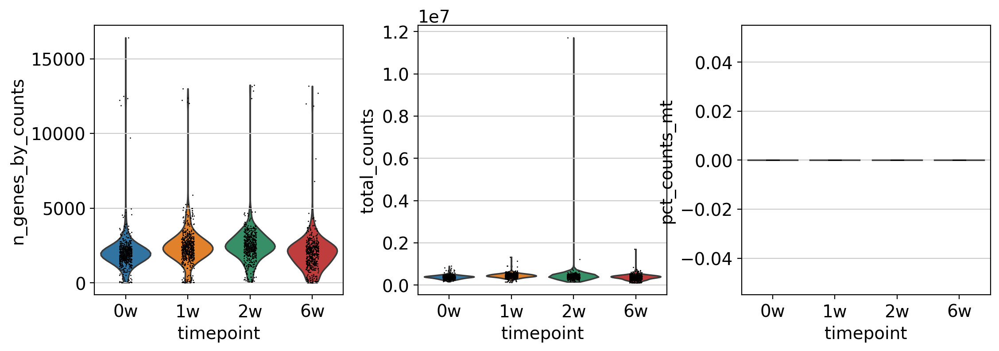

In [44]:
sc.pl.violin(
    adata_103334,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    groupby="timepoint",
    multi_panel=True,
    save="preQC.png"
)

#### Filter dataframe by expression of cells with certain number of expressed genes and certain percentage of MT percentage count since too much indicates dead or dying cells - check dataframe after and generate same violin plots

In [43]:
adata_103334 = adata_103334[adata_103334.obs.n_genes_by_counts > 200, :]
adata_103334 = adata_103334[adata_103334.obs.n_genes_by_counts < 6000, :]
adata_103334 = adata_103334[adata_103334.obs.pct_counts_mt < 10, :]

#### Shape of annotated data table after removal of extreme MT percentage count cells

In [44]:
print("After QC:", adata_103334.shape)

After QC: (2111, 20789)


/tmp/ipykernel_156/1335586627.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


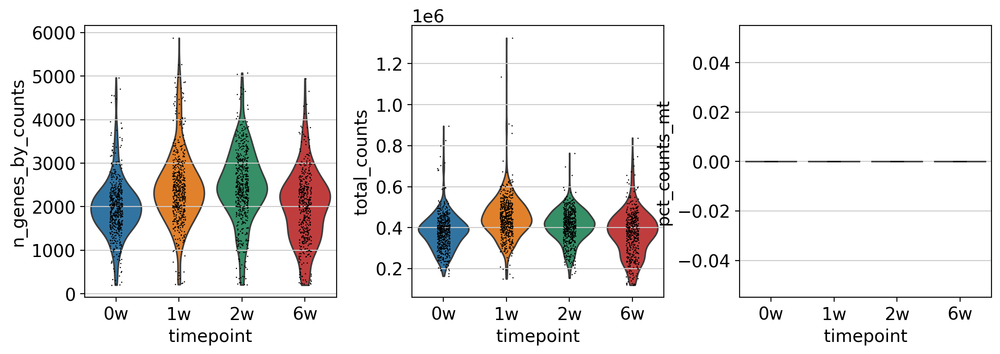

In [47]:
sc.pl.violin(
    adata_103334,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    groupby="timepoint",
    multi_panel=True,
    save="postQC.png"
)

#### Create some graphs that display certain relationships between phenotype based metrics, primarily scatter plots, a joint plot, a violin plot, and a heatmap plot

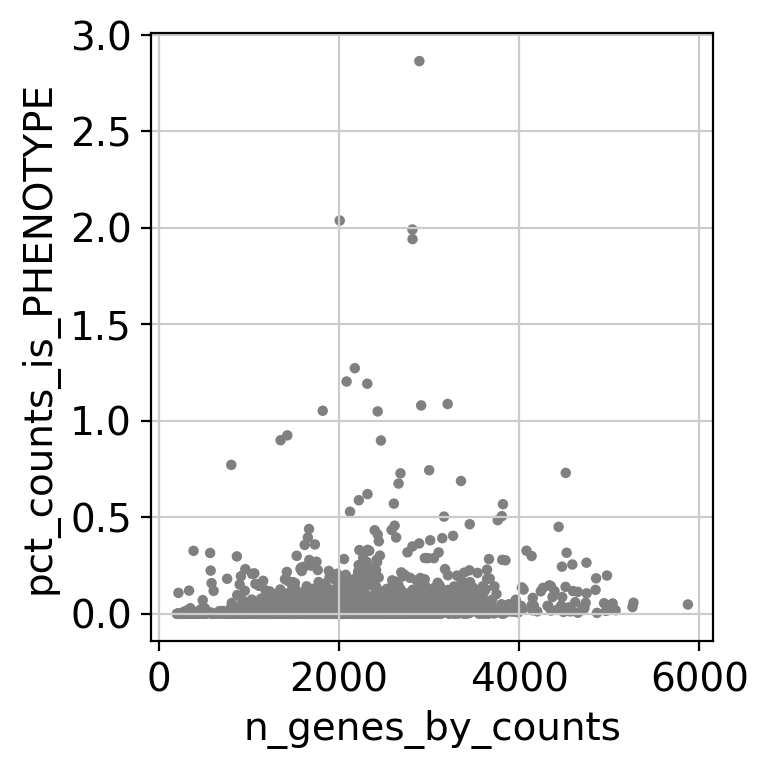

In [48]:
# Plot suggests that fraction of expression from M1 markers is higher when cells have expressed less genes

sc.pl.scatter(
    adata_103334,
    x="n_genes_by_counts",
    y="pct_counts_is_PHENOTYPE",
)

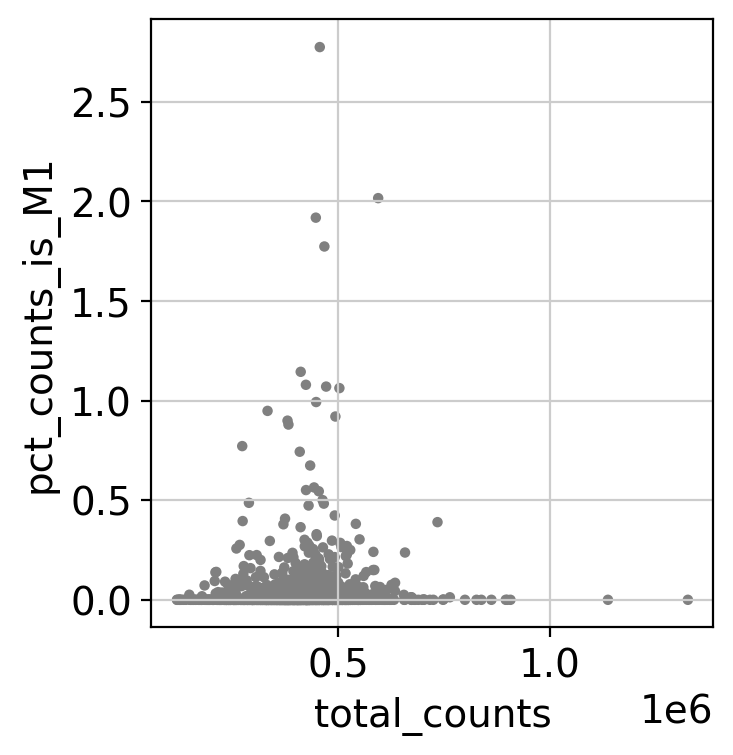

In [49]:
#total expression per cell seems to have potential relationhsip with fraction of M1 marker expression

sc.pl.scatter(
    adata_103334,
    x="total_counts",
    y="pct_counts_is_M1",
)

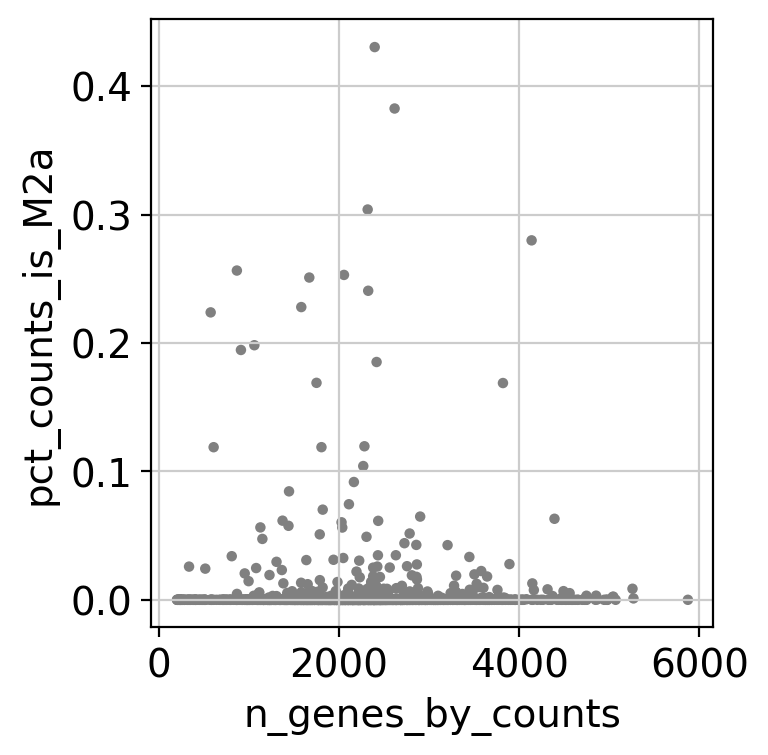

In [50]:
# some continuous range of values perhaps suggested by this graph, or mixture of genes responsible for M1 and M2a
# cells that expressed less genes expressed more M2a genes

sc.pl.scatter(
    adata_103334,
    x="n_genes_by_counts",
    y="pct_counts_is_M2a",
)

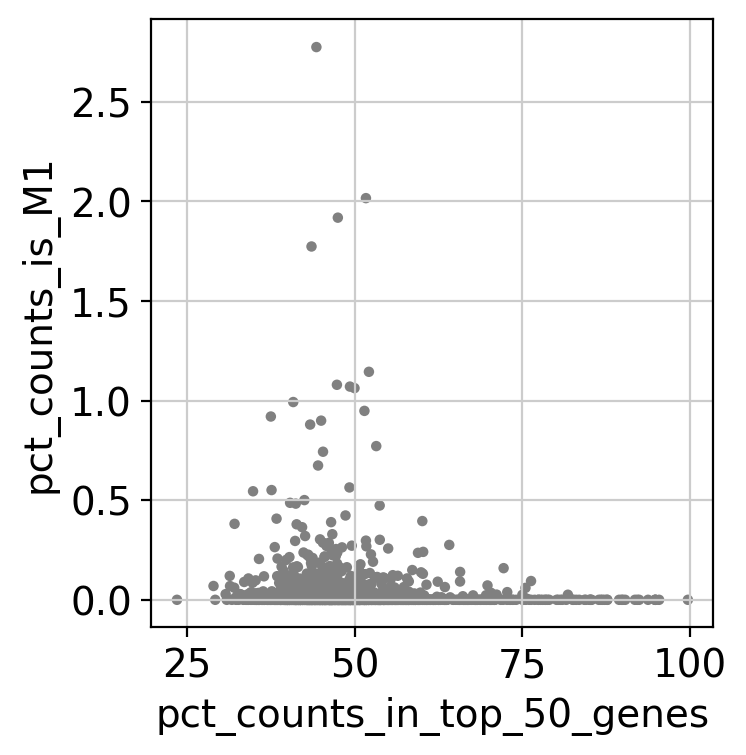

In [51]:
sc.pl.scatter(
    adata_103334,
    x="pct_counts_in_top_50_genes",
    y="pct_counts_is_M1",
)

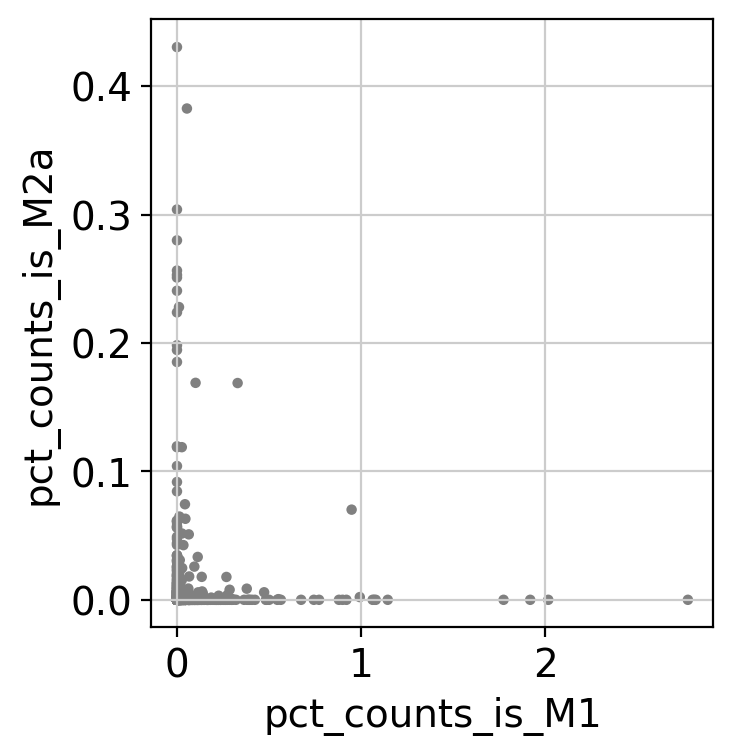

In [52]:
# suggests that fraction of genes expressed that are M1 and M2a are separate to some degree. zero M1 expressed markers yielded more M2a marker expression, vice versa

sc.pl.scatter(
    adata_103334,
    x="pct_counts_is_M1",
    y="pct_counts_is_M2a",
)

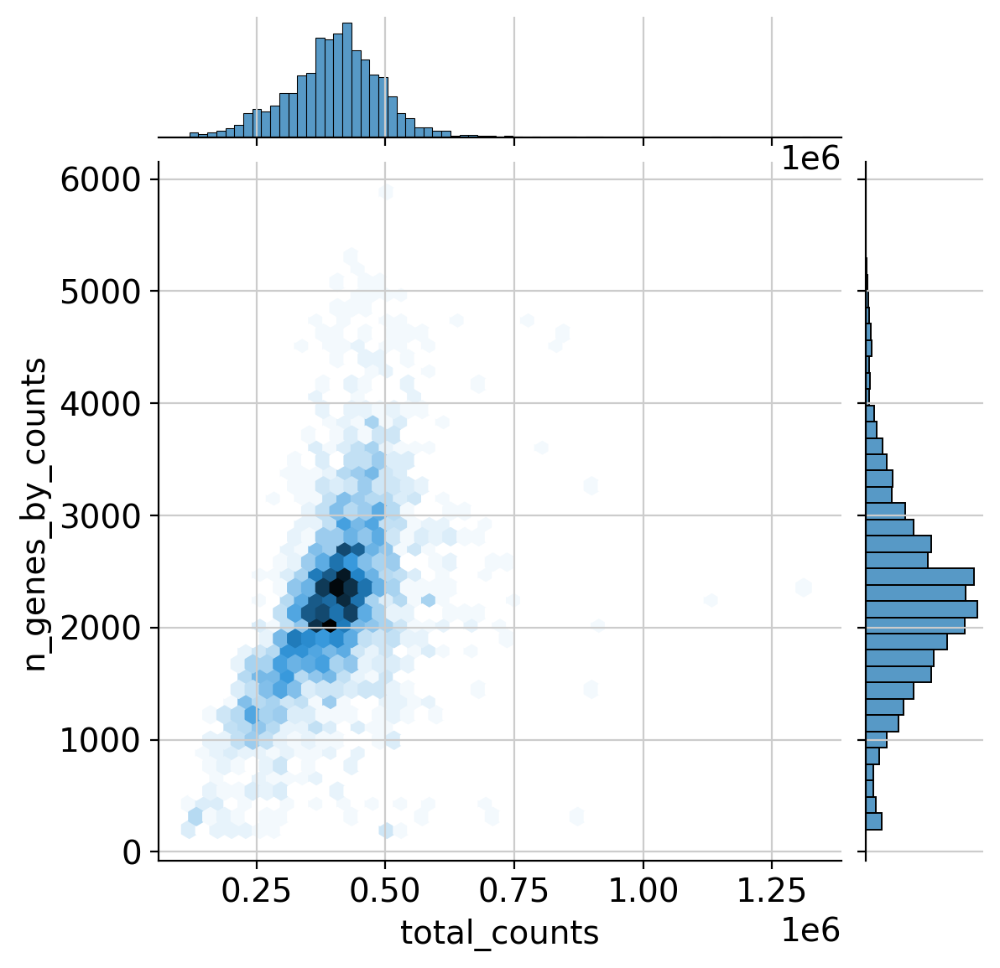

In [53]:
sns.jointplot(
    data=adata_103334.obs,
    x="total_counts",
    y="n_genes_by_counts",
    kind="hex",
).savefig("pairplot.png")

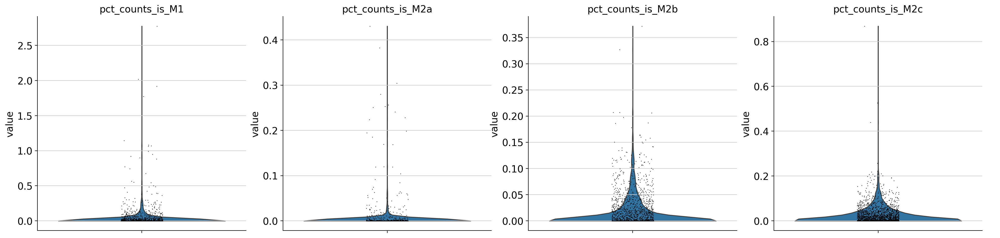

In [54]:
# n_genes_by_counts is number of genes with expression counts >=1
# total counts is the total number of counts for a cell or sum of counts for a gene (if we specify gene)
sc.pl.violin(
    adata_103334,
    keys=[
        "pct_counts_is_M1",
        "pct_counts_is_M2a",
        "pct_counts_is_M2b",
        "pct_counts_is_M2c",
    ],
    multi_panel=True,
)

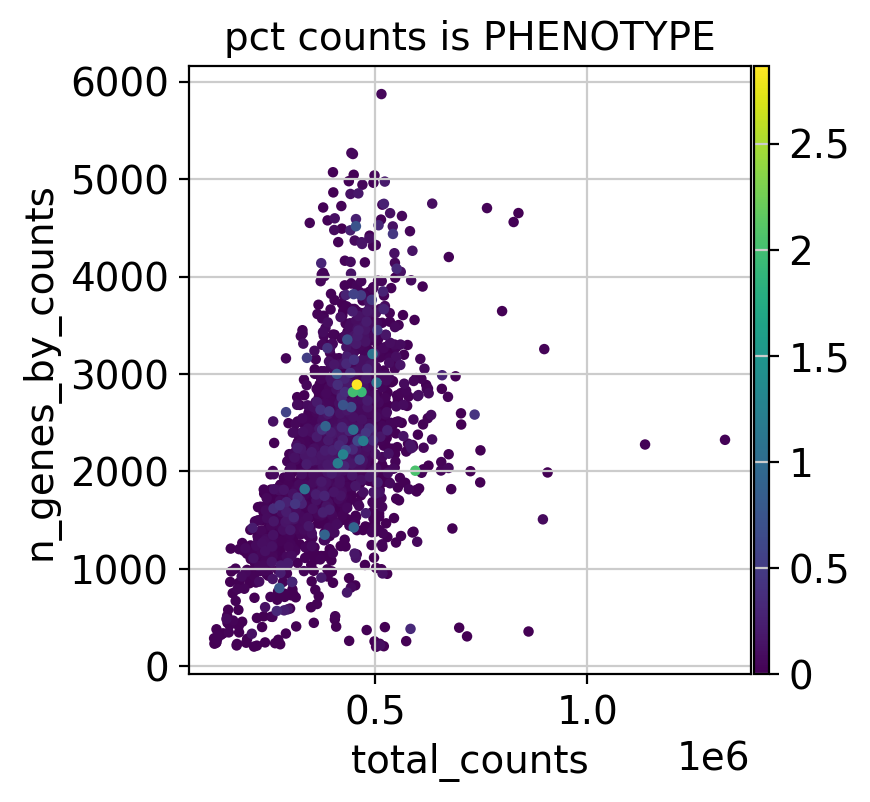

In [55]:
# pct_counts_in_top_50_genes is cumulative percentage of counts from the top 50 most expressed genes
sc.pl.scatter(adata_103334, "total_counts", "n_genes_by_counts", color="pct_counts_is_PHENOTYPE")

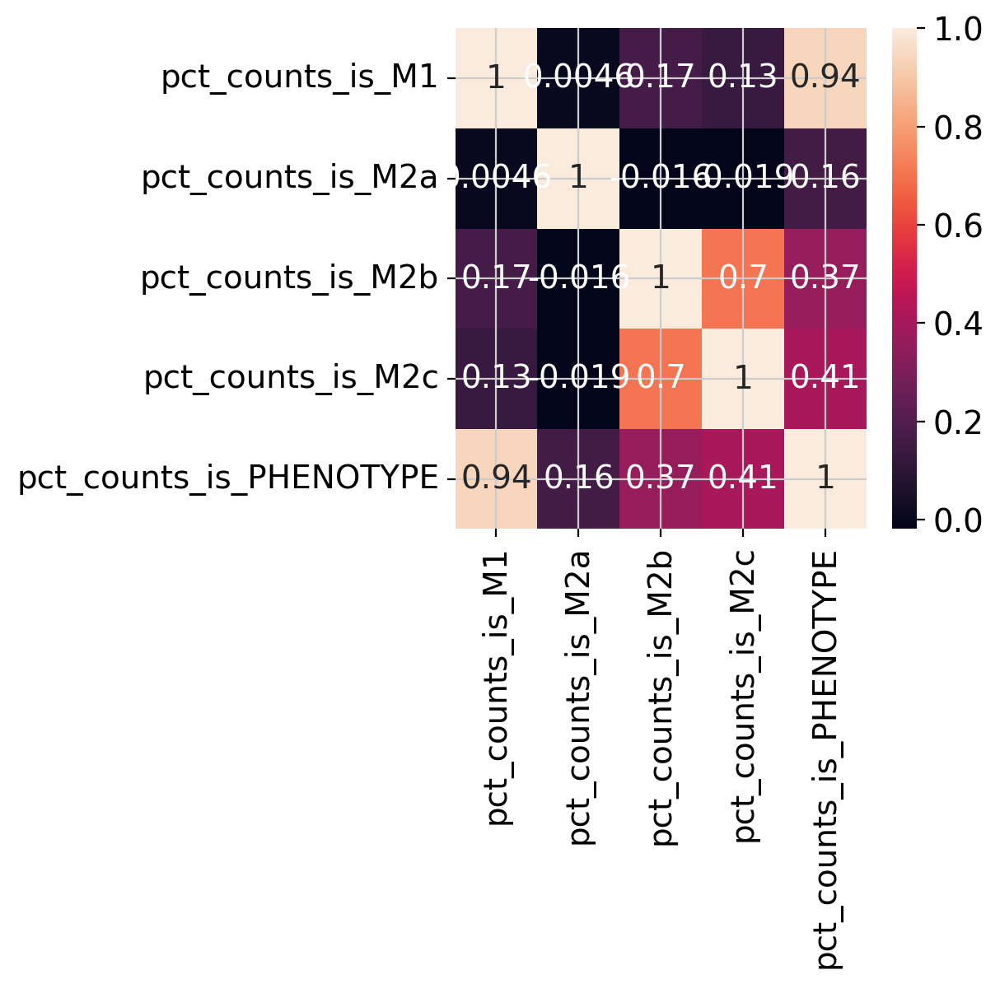

In [56]:
# fraction of expressed genes that are M1 most correlated to M2b (hardly), and M2a most correlated to M2b (hardly), but M2b correlated highly with M2c

qc_cols = [
    "pct_counts_is_M1",
    "pct_counts_is_M2a",
    "pct_counts_is_M2b",
    "pct_counts_is_M2c",
    "pct_counts_is_PHENOTYPE",
]

sns.heatmap(adata_103334.obs[qc_cols].corr(), annot=True)
plt.savefig("heatmap.png")

### Normalize, Log transform, and collect list of highly variable genes (HVGs)

#### Normalizing brings everything to equal scale, log transform compresses extreme values, and derive highly variable genes that likely define clusters, drive underlying structure, and reflect biological differences

/tmp/ipykernel_172/3799598589.py:2: UserWarning: Received a view of an AnnData. Making a copy.
  sc.pp.normalize_total(adata_103334, target_sum=1e4)
/opt/conda/lib/python3.12/site-packages/scanpy/preprocessing/_highly_variable_genes.py:382: RuntimeWarning: invalid value encountered in log
  dispersion = np.log(dispersion)


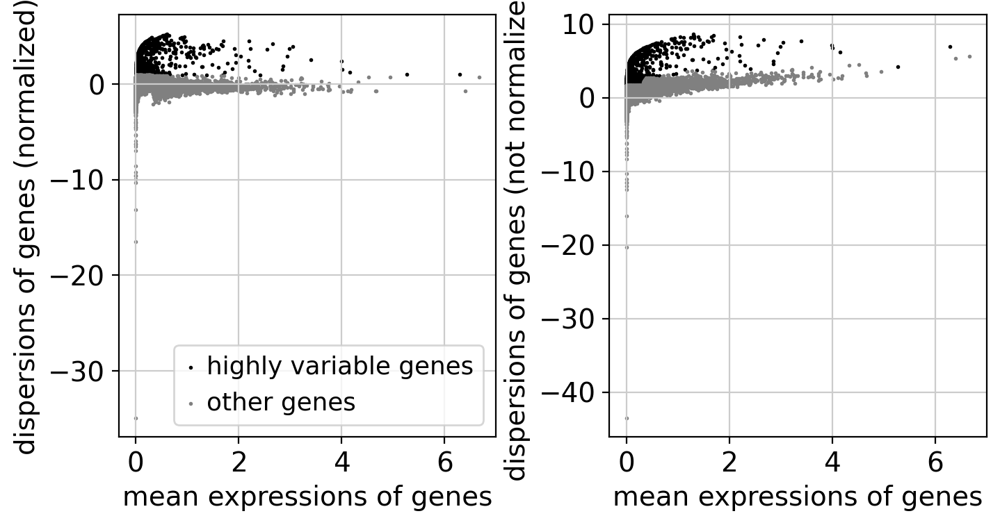

In [45]:
# 1. Normalize per cell
sc.pp.normalize_total(adata_103334, target_sum=1e4)

# 2. Log transform
sc.pp.log1p(adata_103334)

# 3. Find highly variable genes
sc.pp.highly_variable_genes(adata_103334, n_top_genes=2000)

# visualize
sc.pl.highly_variable_genes(adata_103334);

adata_103334.raw = adata_103334

#### We obtain 2000 highly variable genes after normalizing and transforming the gene expression data which was pre filtered by mitochondrial RNA expression after generating our QC metrics. Shown below

In [46]:
# Keep only HVGs for downstream analysis
adata_103334 = adata_103334[:, adata_103334.var.highly_variable]

In [47]:
sc.pp.scale(adata_103334, max_value=10)

/opt/conda/lib/python3.12/functools.py:909: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)


In [48]:
print("HVG count:", adata_103334.var.highly_variable.sum())

HVG count: 2000


## PCA performed on filtered and highly variable genes

#### HVGs are dimensions in our data space, which we'll reduce and visualize variance of cells captured by each principal component

In [61]:
sc.tl.pca(adata_103334, svd_solver='arpack')

#### Variance ratio of each principal component plotted in order

/tmp/ipykernel_156/1976556925.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca_variance_ratio(adata_103334, save=".png")


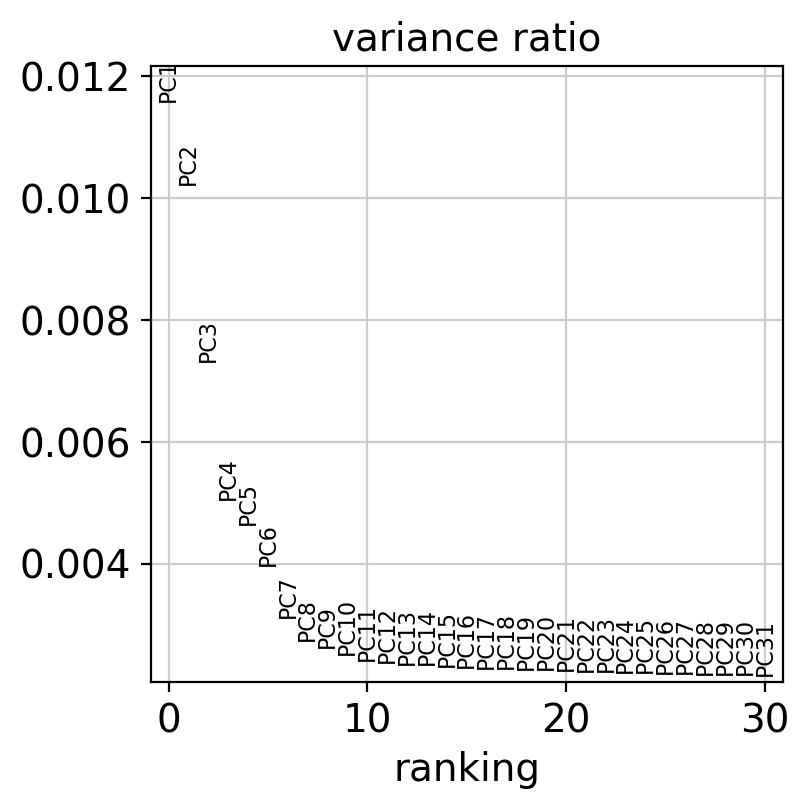

In [62]:
sc.pl.pca_variance_ratio(adata_103334, save=".png")

/tmp/ipykernel_156/1523272259.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca_variance_ratio(adata_103334, log=True, save="_log.png")


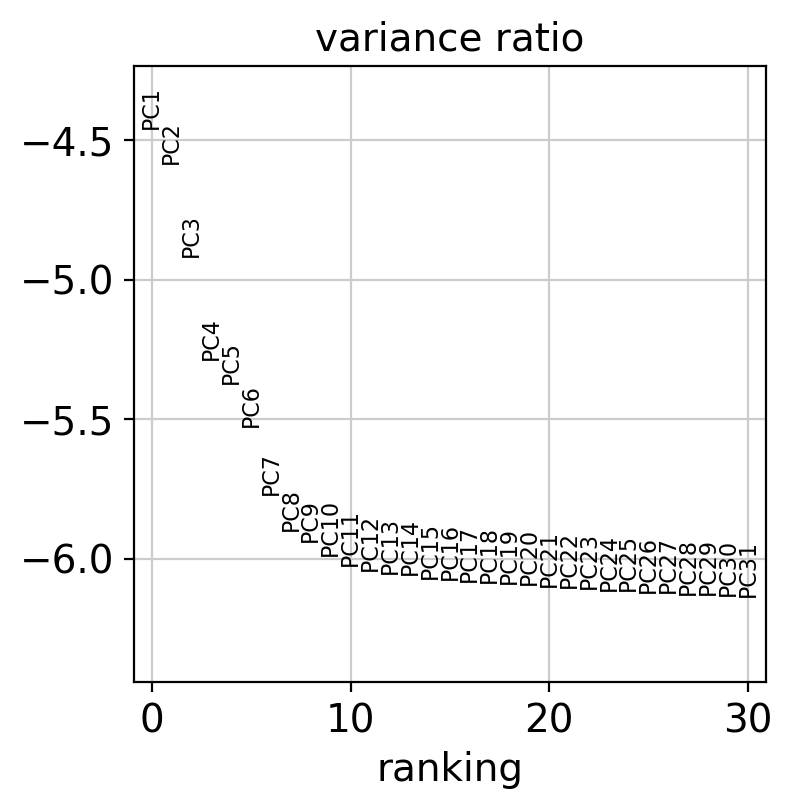

In [63]:
sc.pl.pca_variance_ratio(adata_103334, log=True, save="_log.png")

#### Variance captured for different time points span in different directions mostly between week 1 and other weeks. This indicates some temporal pattern of how cells are represented in lower embedding, indicates some genetic marker dimensions are building variance over time in almost orthogonal directions

/tmp/ipykernel_156/3266988537.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca(adata_103334, color="timepoint", save="_time.png")


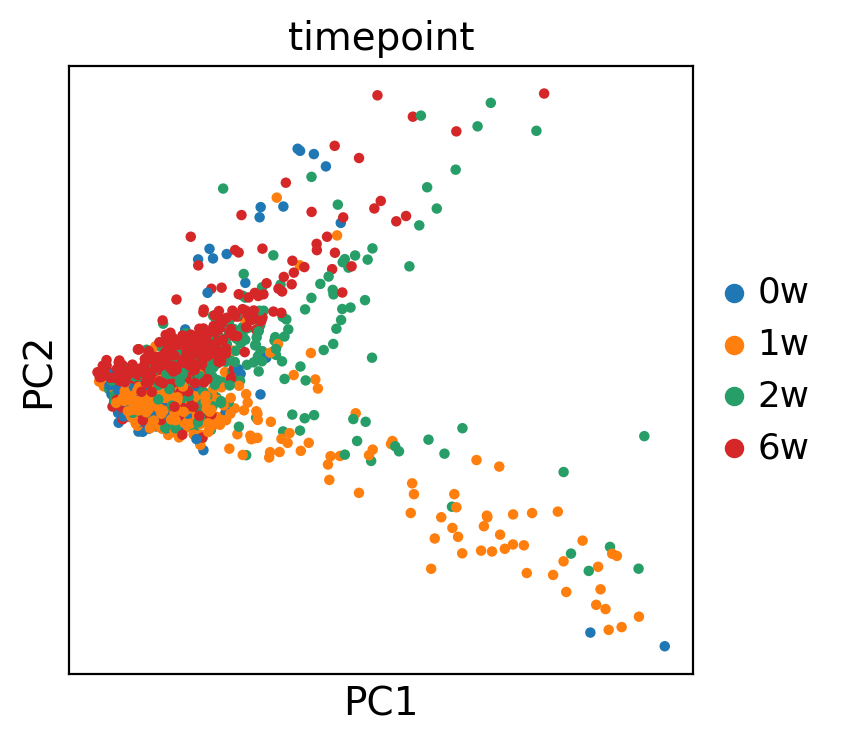

In [64]:
sc.pl.pca(adata_103334, color="timepoint", save="_time.png")

#### PCA result plotted and grouped by phenotype-expression score

/tmp/ipykernel_156/2656355333.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca(adata_103334, color=["M1_score", "M2a_score", "M2b_score", "M2c_score"], save="_phenotype.png")


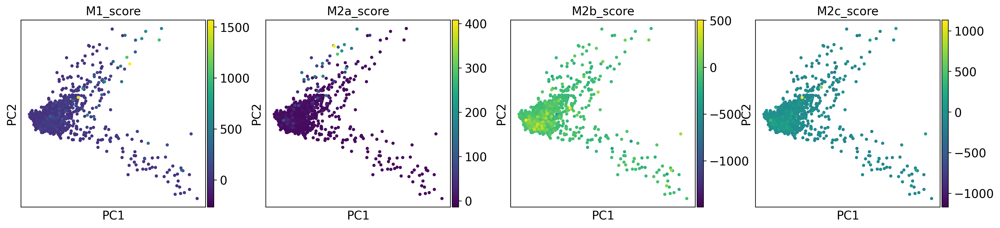

In [65]:
sc.pl.pca(adata_103334, color=["M1_score", "M2a_score", "M2b_score", "M2c_score"], save="_phenotype.png")

### Obtain neighbors graph which UMAP & Leiden clustering utilizes (recall UMAP composes merged graph to be compared to lower embedding graph)

In [49]:
sc.pp.neighbors(adata_103334, n_neighbors=10, n_pcs=20)

/tmp/ipykernel_172/4027109256.py:1: UserWarning: You’re trying to run this on 2000 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  sc.pp.neighbors(adata_103334, n_neighbors=10, n_pcs=20)


## Use UMAP dimensionality reduction to understand what lower graph embedding captures topology of our data space

In [67]:
sc.tl.umap(adata_103334)

#### Overtime in CK-p25 mice model we identify some local areas where cells are distinctly separated from other time points. Note that week 0 and 1 are clustered closer together, as well as some points from the later two clusters. However, we see little to no overlap between first and last two weeks, which indicates a shift in genetic expression in later time points during neurodegeneration

/tmp/ipykernel_156/3594383495.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_103334, color="timepoint", save="_time.png")


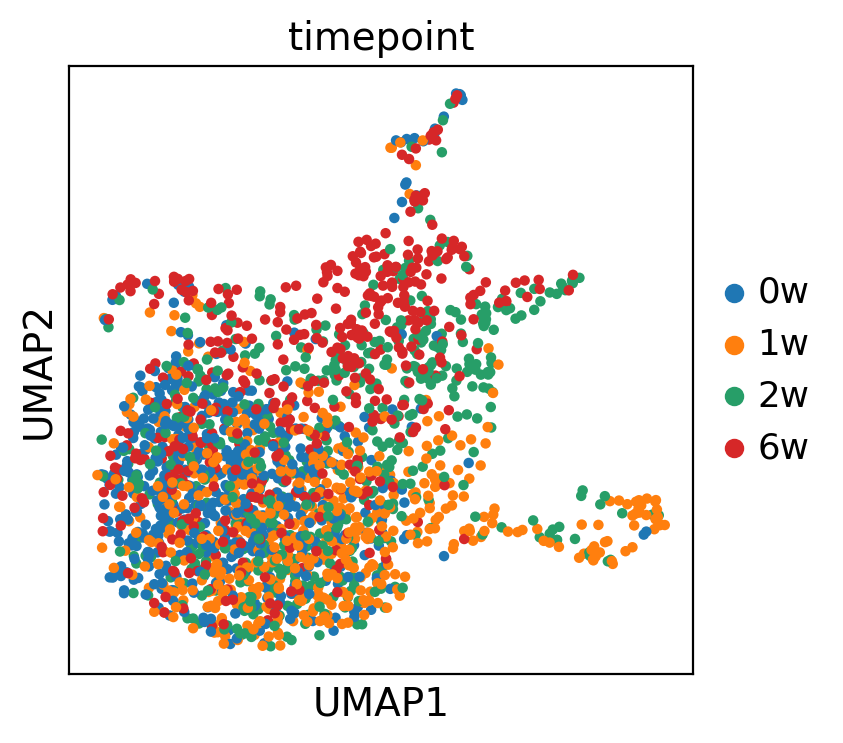

In [68]:
sc.pl.umap(adata_103334, color="timepoint", save="_time.png")

#### Conduct leiden clustering algorithm with resolution 0.5 which dictates how many clusters we get. 0.5-0.8 known to be balanced, while we can also tune this to get sub groups or broader cell groups that umbrella phenotype

In [50]:
sc.tl.leiden(adata_103334, flavor="igraph", resolution=0.5)

#### We see that with moderate resolution that six clusters are visible to us. This could be the 4 clusters mapping spectrum M1 to M2 from our previous marker dictionary motivated by literature, however that would still mean there are two clusters which we're not too familiar with. It is a clean split which indicates that these clusters are transcriptionally different 

/tmp/ipykernel_156/4005801716.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_103334, color="leiden", save="leiden.png")


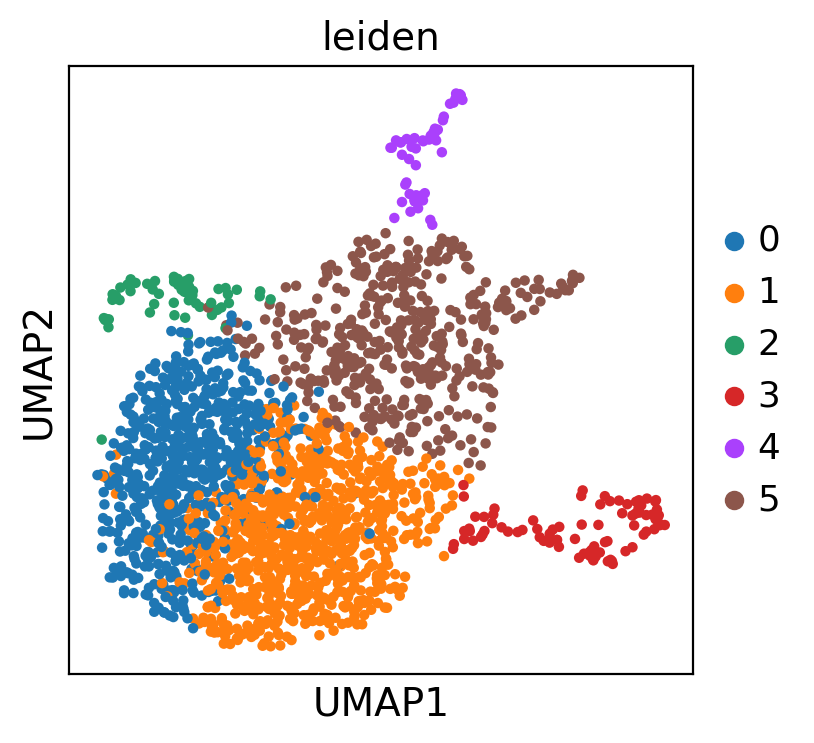

In [70]:
sc.pl.umap(adata_103334, color="leiden", save="leiden.png")

#### M1 and M2a related cells seems to have distinct areas in the graph that house highly expressive cells of these related markers. M1 may indicate some shared marker from all microglia and M1 cells, this isn't the case for M2a. We also see much overlap of cells with little to no markers expressed for M2b and M2c with exception of a few outliers with no visible clustering area

/tmp/ipykernel_156/2391537244.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_103334, color=["M1_score", "M2a_score", "M2b_score", "M2c_score"], save="phenotype.png")


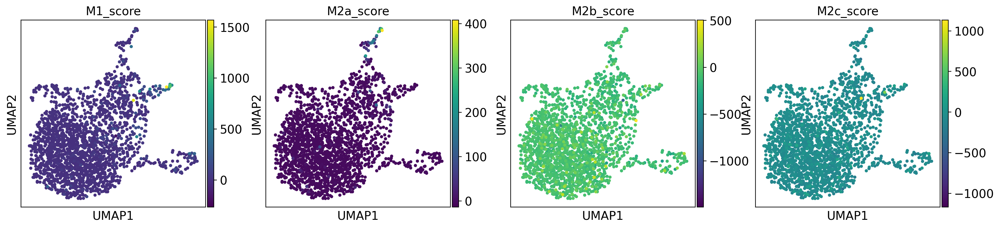

In [71]:
sc.pl.umap(adata_103334, color=["M1_score", "M2a_score", "M2b_score", "M2c_score"], save="phenotype.png")

#### UMAP plotted with three different resolutions: low, moderate, and high

In [72]:
# Commonly and classically, cell type annotation uses those marker genes subsequent to the grouping of the cells into clusters. So, let’s generate a set of clustering solutions which we can then use to annotate our cell types. Here, we will use the Leiden clustering algorithm which will extract cell communities from our nearest neighbours graph.
# Notably, the number of clusters that we define is largely arbitrary, and so is the resolution parameter that we use to control for it. As such, the number of clusters is ultimately bound to the stable and biologically-meaningful groups that we can ultimately distringuish, typically done by experts in the corresponding field or by using expert-curated prior knowledge in the form of markers.
for res in [0.02, 0.5, 1.0]:
    sc.tl.leiden(adata_103334, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")

/tmp/ipykernel_156/268376959.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


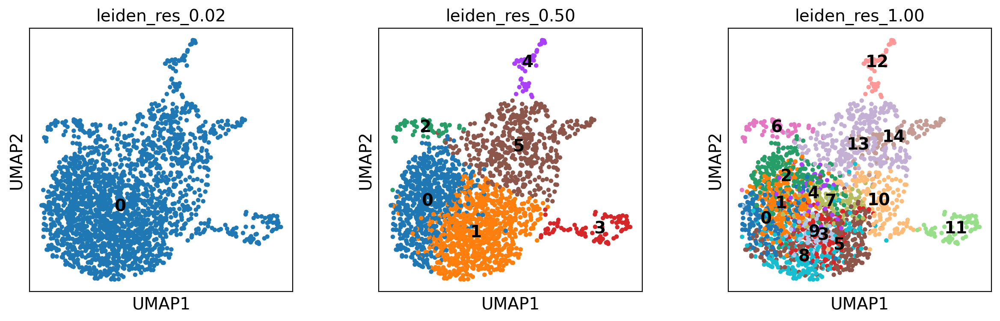

In [73]:
sc.pl.umap(
    adata_103334,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_1.00"],
    legend_loc="on data",
    save="leidensweep.png"
)

## View temporal dynamics 
"How do our clusters change with time?"

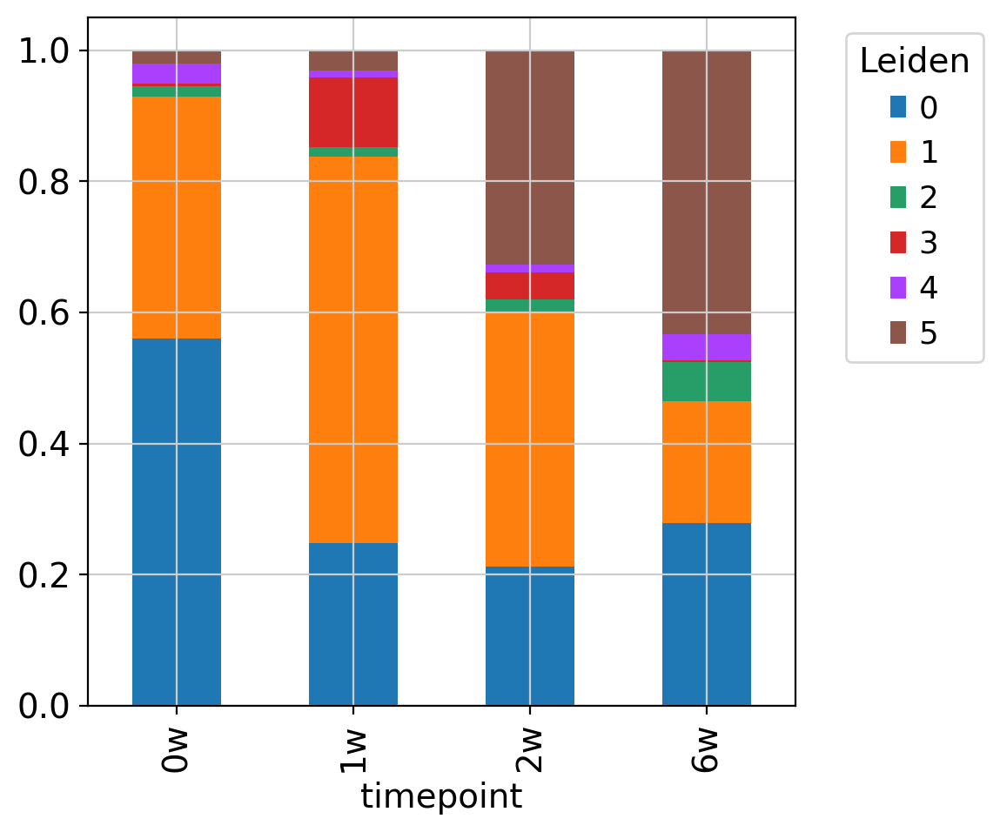

In [56]:
fig, ax = plt.subplots(figsize=(6, 5))

df.plot(kind="bar", stacked=True, ax=ax)

ax.legend(
    title="Leiden",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig("barchart_timeclusters", bbox_inches="tight")

#### Two dominant clusters at first which both die out over time while the clusters with less cells become more populated. Given the context, we can potentially assume that M0 microglia clusters shrink while M2 and M1 clusters grow. We also see a couple clusters which grow larger at intermediate time points over time, which may come from other distinct cell types in a spectrum of phenotypes

### Rank genes in clusters, return top 5 genes per cluster

In [75]:
sc.tl.rank_genes_groups(adata_103334, "leiden", method="wilcoxon")

/tmp/ipykernel_156/635074843.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.rank_genes_groups(adata_103334, n_genes=5, sharey=False, ncols=3, save=".png")


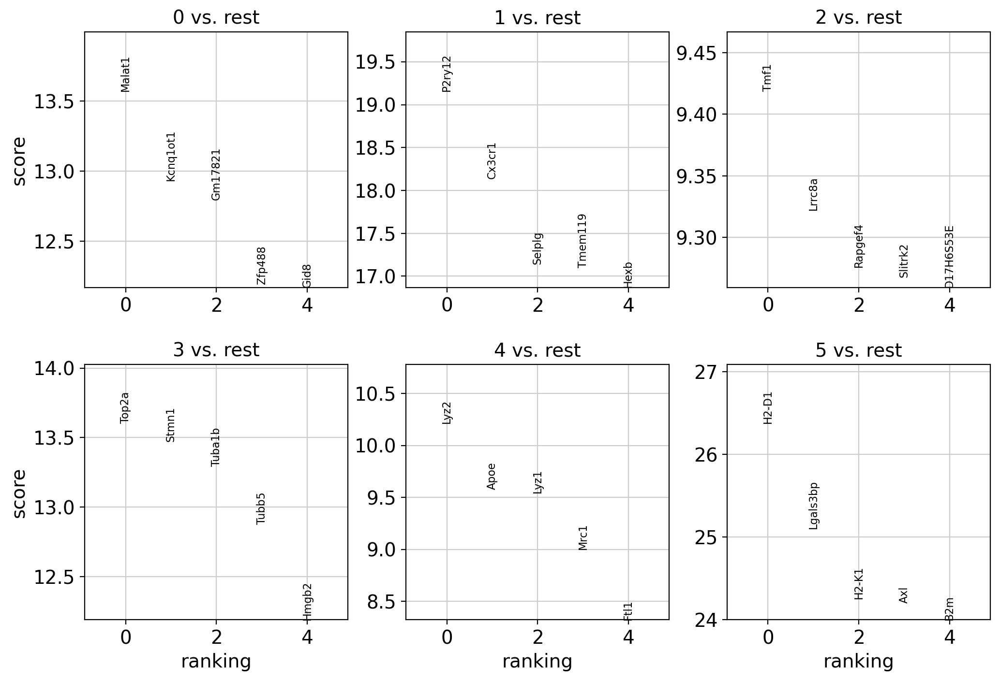

In [76]:
sc.pl.rank_genes_groups(adata_103334, n_genes=5, sharey=False, ncols=3, save=".png")

### UMAP plot grouped by phenotype-marker scores from dictionary mapping

/tmp/ipykernel_156/434628538.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


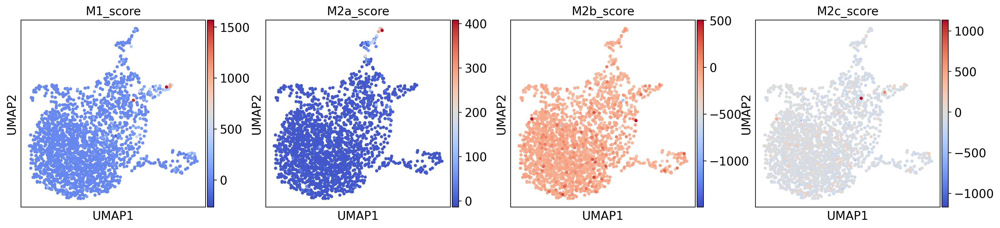

In [77]:
sc.pl.umap(
    adata_103334,
    color=["M1_score", "M2a_score", "M2b_score", "M2c_score"],
    cmap="coolwarm",
    save="_customdict.png"
)

## Dot plots of each cluster based on mapped markers and HVGs 
"Which clusters express which phenotype-marker genes and how strongly?", "Are cluters well divided genetically?"

#### Dot plot of each cluster using M1 and M2a genetic markers derived from literature 

/tmp/ipykernel_156/1508670743.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


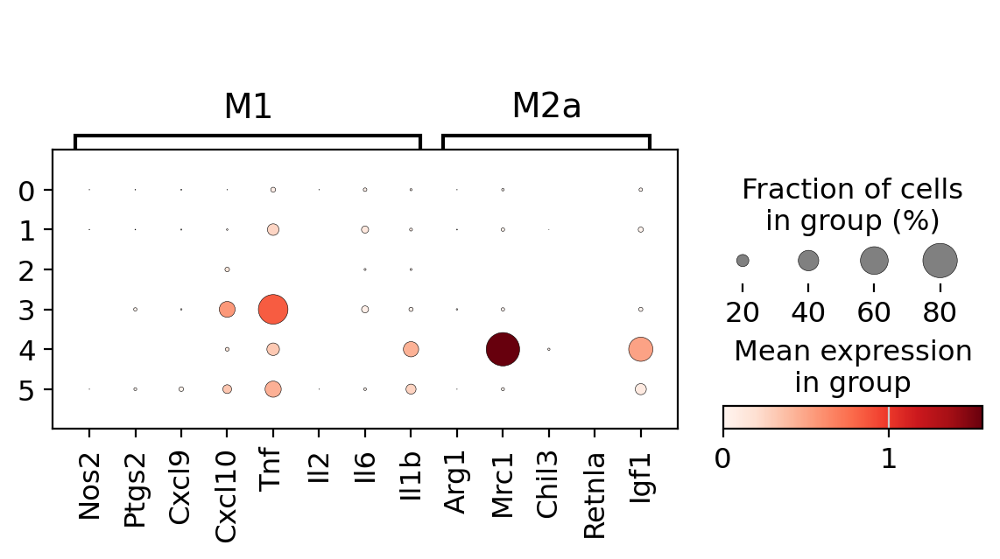

In [78]:
sc.pl.dotplot(
    adata_103334,
    var_names={
        "M1": markers_phenotype_dict["M1"]["Markers"],
        "M2a": markers_phenotype_dict["M2a"]["Markers"],
    },
    groupby="leiden",
    save="_M1M2.png"
)

#### Same plot as above but now include M2b and M2c markers derived from literature as well, and add a hierarchical clustering dendrogram for the six clusters

categories: 0, 1, 2, etc.
var_group_labels: M1, M2a, M2b, etc.


/tmp/ipykernel_156/2018706882.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


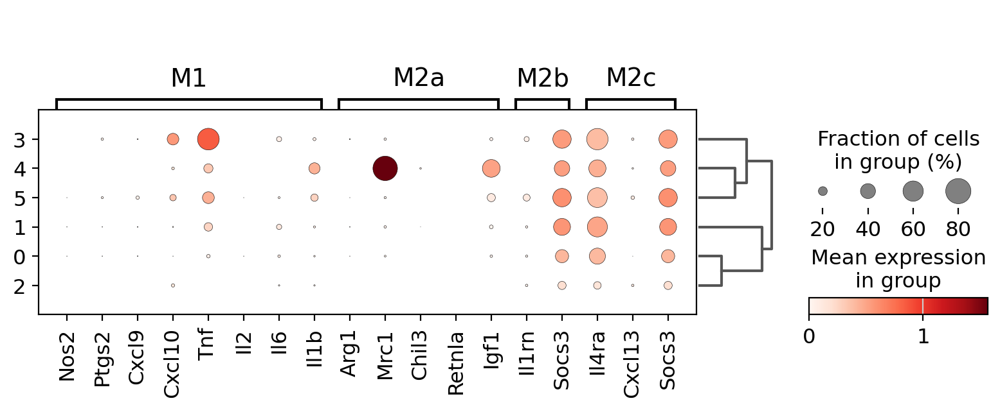

In [79]:
sc.tl.dendrogram(adata_103334, groupby="leiden")

sc.pl.dotplot(
    adata_103334,
    var_names={
        "M1": markers_phenotype_dict["M1"]["Markers"],
        "M2a": markers_phenotype_dict["M2a"]["Markers"],
        "M2b": markers_phenotype_dict["M2b"]["Markers"],
        "M2c": markers_phenotype_dict["M2c"]["Markers"],
    },
    groupby="leiden",
    dendrogram=True,
    save="_phenotypes_hierarchical.png"
)

#### Rotate the first dot plot by 90 degrees

/tmp/ipykernel_156/1619000904.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


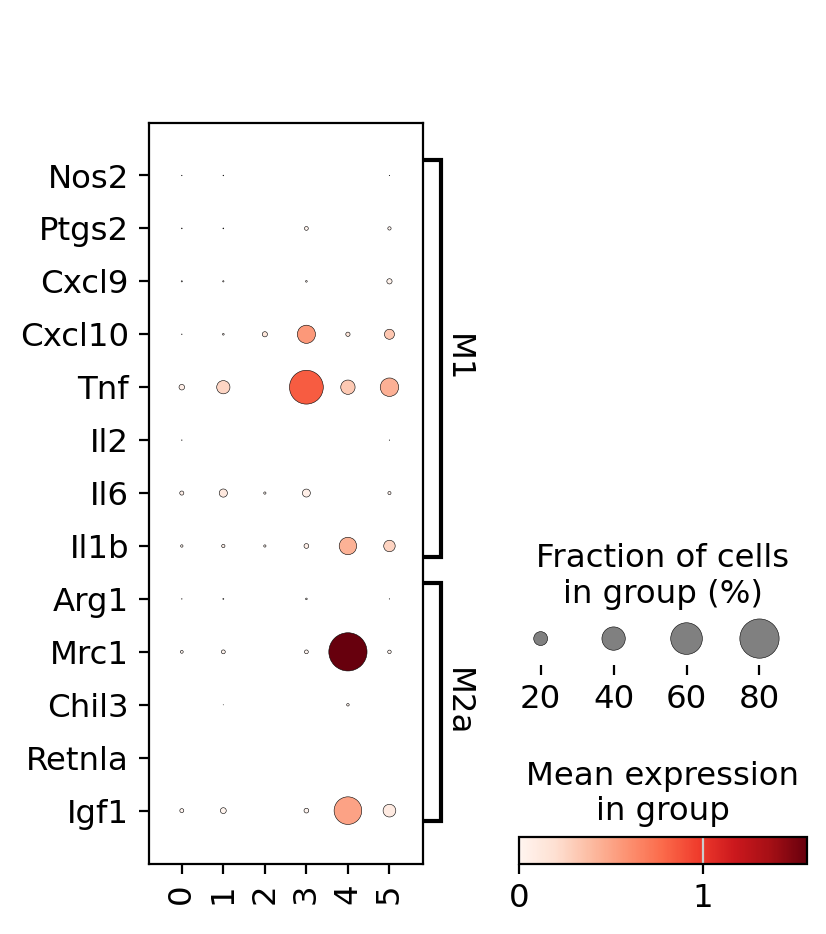

In [80]:
sc.pl.dotplot(
    adata_103334,
    var_names={
        "M1": markers_phenotype_dict["M1"]["Markers"],
        "M2a": markers_phenotype_dict["M2a"]["Markers"],
    },
    groupby="leiden",
    swap_axes=True,
    save="_phenotypes_hierarchical_flip.png"
)

#### Rotate the second dot plot by 90 degrees

categories: 0, 1, 2, etc.
var_group_labels: M1, M2a, M2b, etc.


/tmp/ipykernel_156/343212846.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


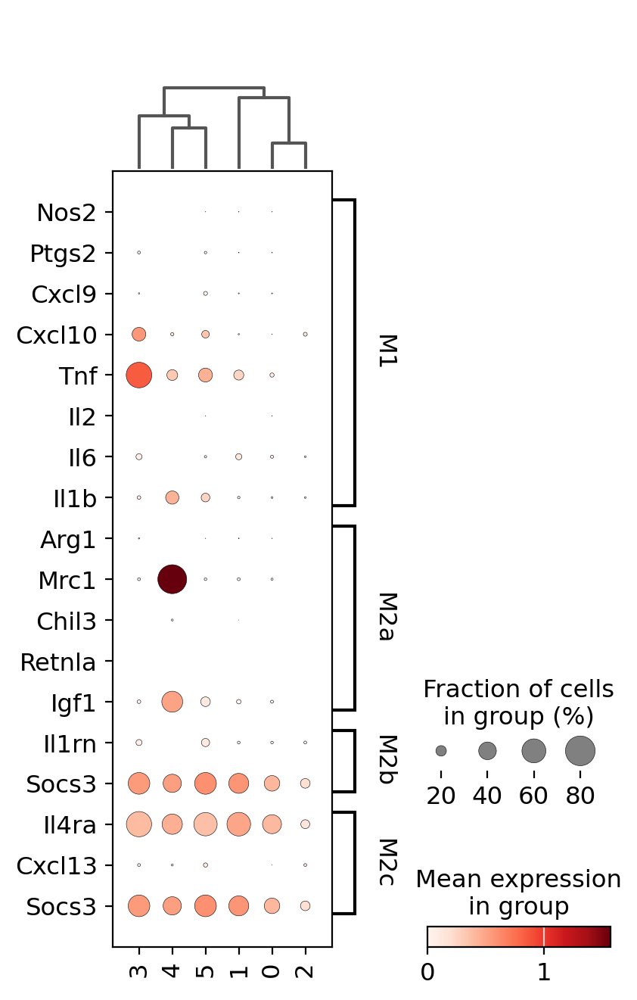

In [81]:
sc.tl.dendrogram(adata_103334, groupby="leiden")

sc.pl.dotplot(
    adata_103334,
    var_names={
        "M1": markers_phenotype_dict["M1"]["Markers"],
        "M2a": markers_phenotype_dict["M2a"]["Markers"],
        "M2b": markers_phenotype_dict["M2b"]["Markers"],
        "M2c": markers_phenotype_dict["M2c"]["Markers"],
    },
    groupby="leiden",
    dendrogram=True,
    swap_axes=True,
    save="_phenotypes_hierarchical_flip.png"
)

### Collect highly ranked genetic markers from each leiden clustering group

In [82]:
marker_genes = {}

for cluster in adata_103334.obs["leiden"].cat.categories:
    genes = sc.get.rank_genes_groups_df(adata_103334, group=cluster)["names"][:5]
    marker_genes[f"Cluster {cluster}"] = genes.tolist()

### Dot Plot of clusters with hierarchical clustering dendrogram, using genetic markers which are highly ranked in each cluster 
"What genes identify with what clusters, are there any that we know from biological literature that correlate with certain phenotype-related biological mechanisms?"

categories: 0, 1, 2, etc.
var_group_labels: Cluster 0, Cluster 1, Cluster 2, etc.


/tmp/ipykernel_156/3121649899.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


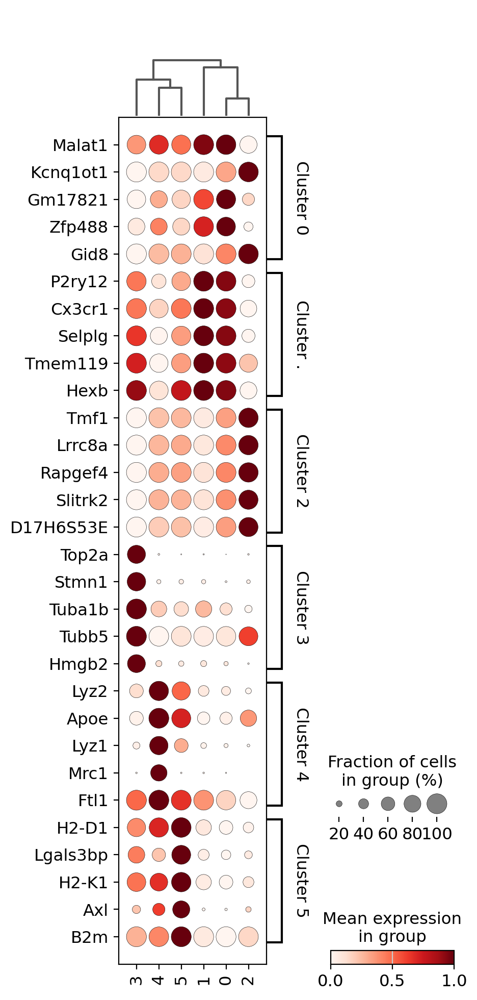

In [84]:
sc.pl.dotplot(
    adata_103334,
    var_names=marker_genes,
    groupby="leiden",
    dendrogram=True,
    standard_scale="var",
    swap_axes=True,
    save="_rankedClusterGenes.png"
)

### UMAP subplots colored by different representative genes of each cluster

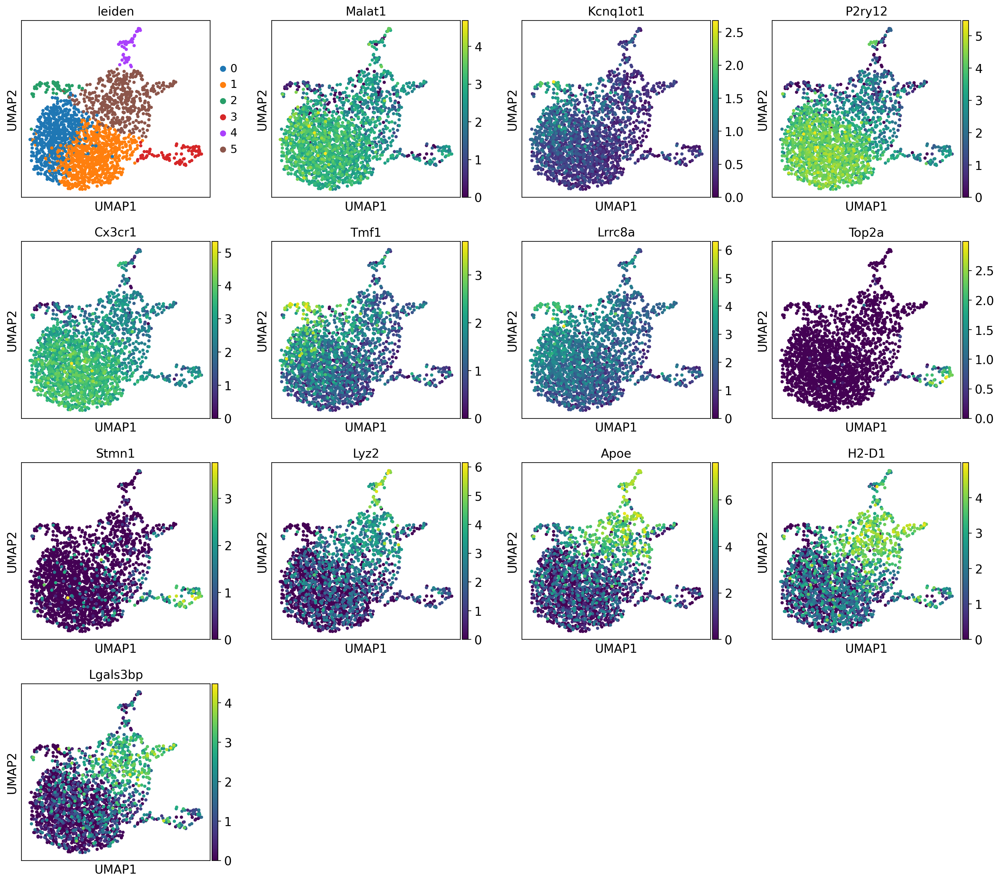

In [117]:
sc.pl.umap(
    adata_103334,
    color=["leiden"] + marker_genes["Cluster 0"][:2] + marker_genes["Cluster 1"][:2] + marker_genes["Cluster 2"][:2] + marker_genes["Cluster 3"][:2] + marker_genes["Cluster 4"][:2] + marker_genes["Cluster 5"][:2]
)

### Heatmap colored by phenotype score per cluster

/tmp/ipykernel_156/3939790110.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_score_summary = adata_103334.obs.groupby("leiden")[score_cols].mean()


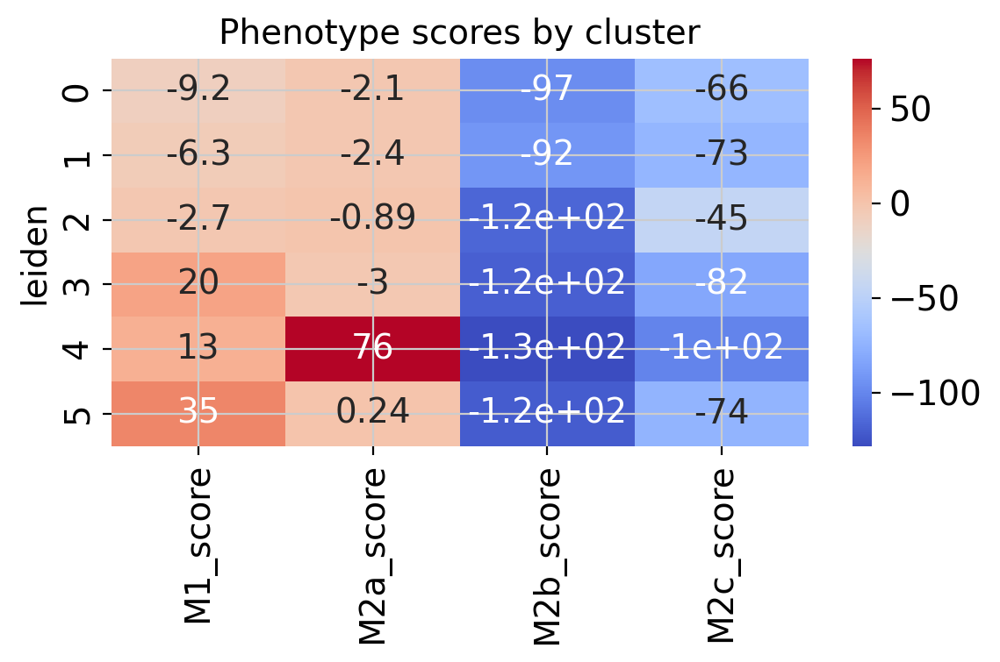

In [87]:
import seaborn as sns
import matplotlib.pyplot as plt

score_cols = ["M1_score", "M2a_score", "M2b_score", "M2c_score"]
cluster_score_summary = adata_103334.obs.groupby("leiden")[score_cols].mean()

plt.figure(figsize=(6,4))
sns.heatmap(cluster_score_summary, annot=True, cmap="coolwarm")
plt.title("Phenotype scores by cluster")
plt.tight_layout()
plt.savefig("heatmap.png")
plt.show()

### UMAP of M1M2 balance score, clipping extreme values so coloration is distinct

/tmp/ipykernel_156/950609700.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


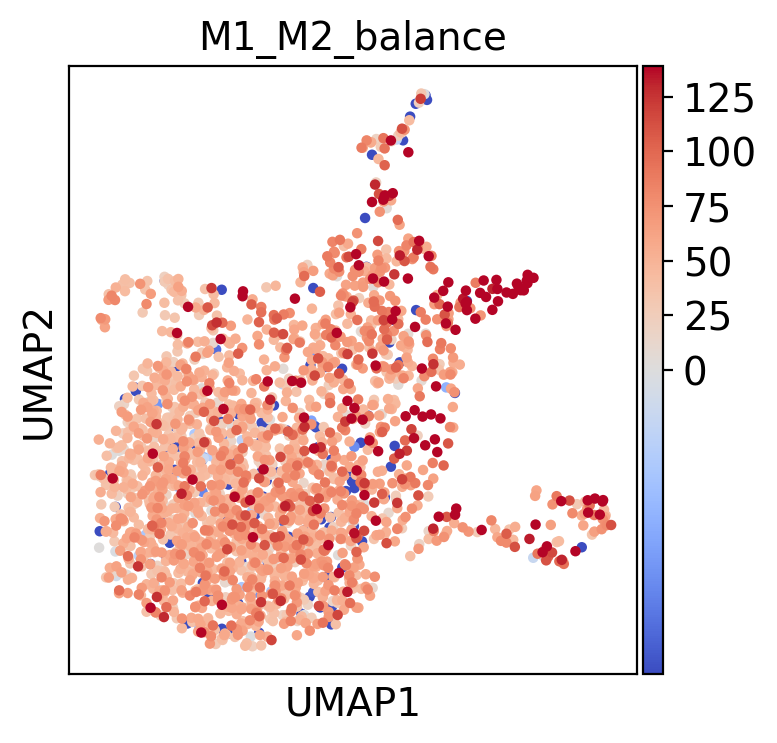

In [101]:
import numpy as np

# clip extreme values
vmin = np.percentile(adata_103334.obs["M1_M2_balance"], 5)
vmax = np.percentile(adata_103334.obs["M1_M2_balance"], 95)

sc.pl.umap(
    adata_103334,
    color="M1_M2_balance",
    cmap="coolwarm",
    vcenter=0,
    vmin=vmin,
    vmax=vmax,
    save="_M1M2continuous.png"
)

## Sources found in `bibliography.bib`